# Mark space per shank — sanity check against the spyglass spikes panel

Plots every spike the decoder's **encoder process** logged, one figure per sort group,
as a grid of channel-vs-channel amplitude scatters. This is the same view as the spikes
panel in spyglass, so the two can be compared by eye.

## What a "mark" is here

For each spike the encoder does this (`encoder_process._compute_mark`):

1. Find which channel in the sort group has the largest peak.
2. Note the *time index* of that peak.
3. Read the waveform value on **every** channel at that one time index.

So `mark_dim_3` is the amplitude on channel 3 of the sort group, sampled at the moment
the strongest channel peaked. That vector is the mark. Clusters — putative units — show
up as blobs sitting off the diagonal in a channel-vs-channel scatter.

## One thing to expect before you look

The config sets `use_channel_dist_from_max_amp: 2`. For any sort group with more than
5 channels, every channel further than 2 away from the peak channel is **zeroed out**
before the mark is stored. On a 12-channel shank that means each spike keeps 5 real
amplitudes and 7 exact zeros.

Consequence: in a lot of channel pairs, both values are exactly 0 and the point carries
no information. Those points are dropped per panel and the surviving count is printed on
each panel as `n=…`. A panel with a small `n` is not a bug — it means those two channels
are rarely both near the peak. **Spyglass does not do this zeroing**, so spyglass will
show points where this notebook shows none.

In [1]:
import os, glob, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

PAL  = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100',
        '#e87ba4', '#008300', '#4a3aa7', '#e34948']
INK, INK2, MUTED = '#0b0b0b', '#52514e', '#898781'
GRID, SURF, BASE = '#e1e0d9', '#fcfcfb', '#c3c2b7'
plt.rcParams.update({
    'figure.facecolor': SURF, 'axes.facecolor': SURF, 'savefig.facecolor': SURF,
    'axes.edgecolor': BASE, 'axes.labelcolor': INK2, 'axes.titlecolor': INK,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 2.0, 'font.size': 10.5, 'legend.frameon': False,
    'figure.dpi': 110,
})
def style_ax(ax):
    ax.set_axisbelow(True)
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)

## 1. Pick the run

`RUN_DIR` can hold several separate decoder runs. `RUN_PREFIX` selects one; leave it
`None` to take the newest merged file in the folder.

In [2]:
# ---------------- run selection ----------------
RUN_DIR    = '/media/ssd1/decoder_output/Vinnie/20260812_r3'
RUN_PREFIX = '20260909_155603_Vinnie_hex_realtime_decoding'   # None -> newest *.rec_merged.h5

if RUN_PREFIX is None:
    cands = sorted(glob.glob(os.path.join(RUN_DIR, '*.rec_merged.h5')))
    assert cands, f'no *.rec_merged.h5 in {RUN_DIR}'
    RUN_PREFIX = os.path.basename(cands[-1]).replace('.rec_merged.h5', '')

REC = os.path.join(RUN_DIR, RUN_PREFIX + '.rec_merged.h5')
cfg = yaml.safe_load(open(glob.glob(os.path.join(RUN_DIR, RUN_PREFIX + '*.config.yaml'))[0]))

N_MARK_DIMS = cfg['encoder']['mark_dim']                       # channels per sort group
CH_DIST     = cfg['encoder']['use_channel_dist_from_max_amp']  # the zeroing radius
MARK_COLS   = [f'mark_dim_{i}' for i in range(N_MARK_DIMS)]

print(f'run    {RUN_PREFIX}')
print(f'marks  {N_MARK_DIMS} channels per sort group')
print(f'keeps  peak channel +/- {CH_DIST}  ->  {2*CH_DIST + 1} non-zero channels per spike'
      f'  (for groups with more than {2*CH_DIST + 1} channels)')

run    20260909_155603_Vinnie_hex_realtime_decoding
marks  12 channels per sort group
keeps  peak channel +/- 2  ->  5 non-zero channels per spike  (for groups with more than 5 channels)


## 2. Load the spikes

The marks live in `rec_3` (`ENCODER_OUTPUT`) — **one row per spike**, not per time bin.
These tables are written in HDF5 *fixed* format, so the whole table has to be read and
then trimmed; `columns=` is not supported on read.

Every spike in `rec_3` is kept. The `encode_spike` and `sent_to_decoder` flags are loaded
too, but only reported, not used as filters.

In [3]:
# ---------------- load rec_3 and trim ----------------
KEEP = ['timestamp', 'elec_grp_id', 'encode_spike', 'sent_to_decoder'] + MARK_COLS

spikes = pd.read_hdf(REC, 'rec_3')          # fixed format: must read in its entirety
spikes = spikes[KEEP].copy()
gc.collect()

SORT_GROUPS = sorted(spikes.elec_grp_id.unique())
counts = spikes.groupby('elec_grp_id').size()

print(f'{len(spikes):,} spikes across {len(SORT_GROUPS)} sort groups\n')
print('  sort group   spikes    encoding   sent to decoder')
for g in SORT_GROUPS:
    s = spikes[spikes.elec_grp_id == g]
    print(f'  {g:>10}   {len(s):>7,}   {int(s.encode_spike.sum()):>7,}   {int(s.sent_to_decoder.sum()):>13,}')

amps = spikes[MARK_COLS].to_numpy()
print(f'\namplitude range across all spikes and channels: {np.nanmin(amps):.1f} .. {np.nanmax(amps):.1f} (raw units)')
del amps; gc.collect()

877,161 spikes across 10 sort groups

  sort group   spikes    encoding   sent to decoder
           2   192,274   117,281         192,274
           5   134,515    78,047         134,515
           8    34,806    24,258          34,806
          12   122,439    58,273         122,439
          15   141,839    91,757         141,839
          18    81,105    50,067          81,105
          22    52,073    20,775          52,073
          25     8,881     4,875           8,881
          28    81,667    31,050          81,667
          31    27,562    13,649          27,562

amplitude range across all spikes and channels: -4999.2 .. 6389.6 (raw units)


0

## 3. The plot

One figure per sort group. The grid holds the lower triangle of the channel-by-channel
matrix, so every unordered pair of channels gets exactly one panel — 66 panels for a
12-channel group. In the panel at row `i`, column `j`: x is the amplitude on channel `j`,
y is the amplitude on channel `i`.

- Each dot is one spike, drawn small and nearly transparent so dense regions go dark.
- Points that are exactly 0 on both axes are dropped. `n=` in the corner is how many
  spikes actually survived into that panel.
- Axes are in raw stored units, with no conversion to microvolts.

### About the axis limits

Each panel scales to its own data, **but not to its full range.** In this run the median
non-zero amplitude is around 90 while the largest is about 6,400 — a handful of huge
outliers, well under 0.1% of spikes. Scaling to the true min/max squashes every real
spike into a single dot at the origin and the figure tells you nothing.

So each panel scales to the central `AXIS_PCT` of its own points (99.5% by default) and
lets the rare outliers fall outside the view. The lower edge is always pulled down to
include 0, so the origin stays visible as a reference. Set `AXIS_PCT = None` to go back
to true full-range autoscaling.

In [4]:
DOT_SIZE  = 1.5     # marker area in points^2
DOT_ALPHA = 0.06    # low, so overlapping spikes accumulate into dark regions
PANEL_IN  = 1.6     # inches per panel
AXIS_PCT  = 99.5    # central percentage of points each panel scales to; None -> full range


def _limits(v, pct):
    """Axis limits for one channel: robust to outliers, and always including 0."""
    if v.size == 0:
        return -1.0, 1.0
    if pct is None:
        lo, hi = float(v.min()), float(v.max())
    else:
        lo, hi = np.percentile(v, [100 - pct, pct])
    lo = min(float(lo), 0.0)                 # keep the origin in view
    if hi <= lo:
        hi = lo + 1.0
    pad = 0.04 * (hi - lo)
    return lo - pad, hi + pad


def _live_pair(m, i, j):
    """x = channel j, y = channel i, with spikes that are exactly 0 on both dropped."""
    x, y = m[:, j], m[:, i]
    live = ~((x == 0) & (y == 0))
    return x[live], y[live]


def pair_limits(m, axis_pct=AXIS_PCT):
    """Axis limits for every lower-triangle channel pair: {(i, j): ((xlo, xhi), (ylo, yhi))}.

    Computed once on the whole session and handed to `plot_sort_group(limits=...)` so a
    series of time windows all share the same axes."""
    n_ch = m.shape[1]
    lims = {}
    for i in range(1, n_ch):
        for j in range(i):
            x, y = _live_pair(m, i, j)
            lims[(i, j)] = (_limits(x, axis_pct), _limits(y, axis_pct))
    return lims


def plot_sort_group(group, spikes, mark_cols, dot_size=DOT_SIZE, dot_alpha=DOT_ALPHA,
                    panel_in=PANEL_IN, axis_pct=AXIS_PCT,
                    limits=None, title=None, verbose=True):
    """Lower-triangle grid of channel-vs-channel mark amplitudes for one sort group.

    `limits`  : output of `pair_limits`; when given, every panel uses those fixed axes
                instead of autoscaling to its own points.
    `title`   : replaces the default suptitle.
    `verbose` : print the per-panel survivor / clipping summary.
    """
    m = spikes.loc[spikes.elec_grp_id == group, mark_cols].to_numpy(np.float64)
    n_ch = m.shape[1]

    # channel 0 is never on the y axis and the last channel is never on the x axis,
    # so the grid is one smaller than the channel count in each direction
    n = n_ch - 1
    fig, axes = plt.subplots(n, n, figsize=(n * panel_in, n * panel_in))
    fig.suptitle(title or f'sort group {group}  —  {len(m):,} spikes', fontsize=14)

    survivors, clipped = [], 0
    for i in range(1, n_ch):            # y channel
        for j in range(n_ch - 1):       # x channel
            ax = axes[i - 1, j]
            if j >= i:                  # keep only the lower triangle
                ax.set_visible(False)
                continue

            # a spike says nothing about this pair when the zeroing rule blanked both
            x, y = _live_pair(m, i, j)
            survivors.append(x.size)

            ax.scatter(x, y, s=dot_size, alpha=dot_alpha, c=PAL[0],
                       linewidths=0, rasterized=True)

            if limits is None:
                (xlo, xhi), (ylo, yhi) = _limits(x, axis_pct), _limits(y, axis_pct)
            else:
                (xlo, xhi), (ylo, yhi) = limits[(i, j)]
            ax.set_xlim(xlo, xhi); ax.set_ylim(ylo, yhi)
            clipped += int(((x < xlo) | (x > xhi) | (y < ylo) | (y > yhi)).sum())

            style_ax(ax)
            ax.tick_params(labelsize=6, length=2)
            ax.text(0.03, 0.96, f'n={x.size:,}', transform=ax.transAxes,
                    ha='left', va='top', fontsize=6,
                    color=MUTED if x.size else PAL[7])

            if j == 0:
                ax.set_ylabel(f'ch {i}', fontsize=8)
            if i == n_ch - 1:
                ax.set_xlabel(f'ch {j}', fontsize=8)

    fig.tight_layout(rect=[0, 0, 1, 0.98])

    if not verbose:
        return fig
    s = np.array(survivors)
    total = s.sum()
    print(f'sort group {group}: {len(m):,} spikes over {len(s)} channel pairs.')
    print(f'  surviving the both-zero drop, per panel: '
          f'min {s.min():,}  median {int(np.median(s)):,}  max {s.max():,}'
          f'   ({int((s == 0).sum())} empty panel(s))')
    if axis_pct is not None:
        print(f'  outside the {axis_pct}% view and therefore not drawn: '
              f'{clipped:,} of {total:,} plotted points ({100 * clipped / max(total, 1):.2f}%)')
    return fig

## 4. Every sort group

Ten figures, one after another. These are large: 66 panels each, hundreds of thousands
of points. Expect this cell to take a couple of minutes.

sort group 2: 192,274 spikes over 66 channel pairs.
  surviving the both-zero drop, per panel: min 3,142  median 175,095  max 191,528   (0 empty panel(s))
  outside the 99.5% view and therefore not drawn: 78,576 of 8,630,855 plotted points (0.91%)


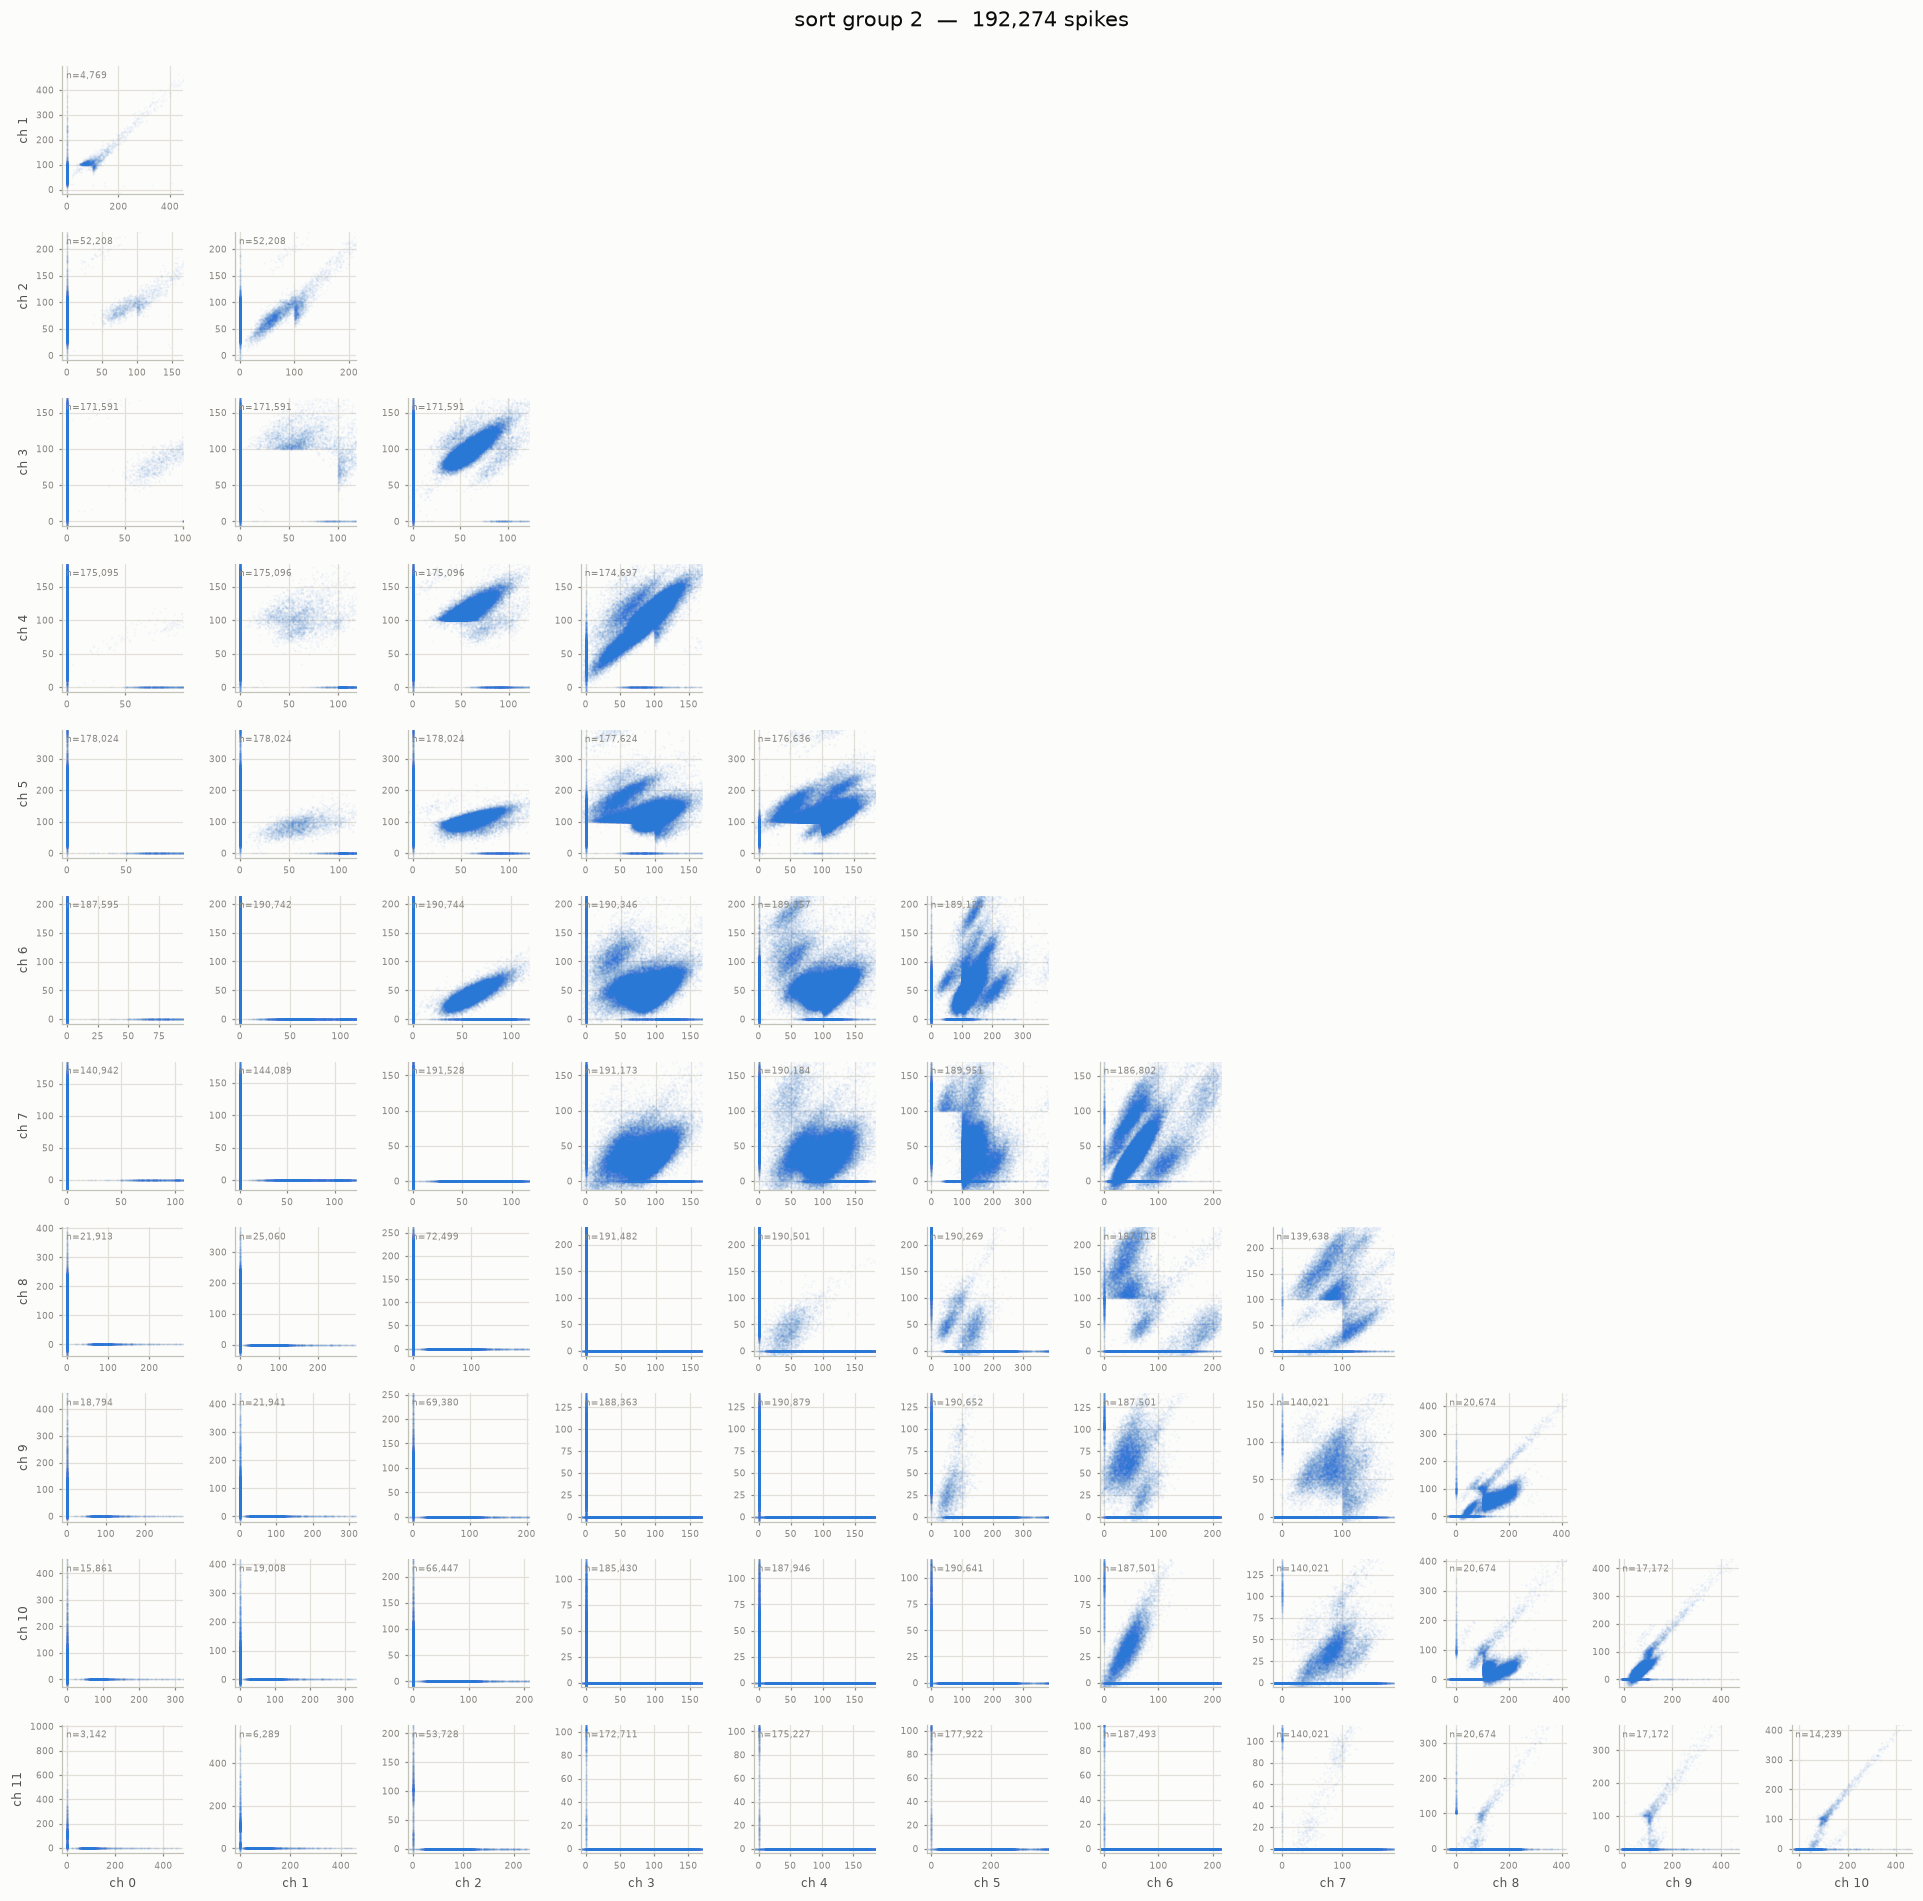

sort group 5: 134,515 spikes over 66 channel pairs.
  surviving the both-zero drop, per panel: min 1,818  median 123,781  max 134,012   (0 empty panel(s))
  outside the 99.5% view and therefore not drawn: 56,175 of 6,034,663 plotted points (0.93%)


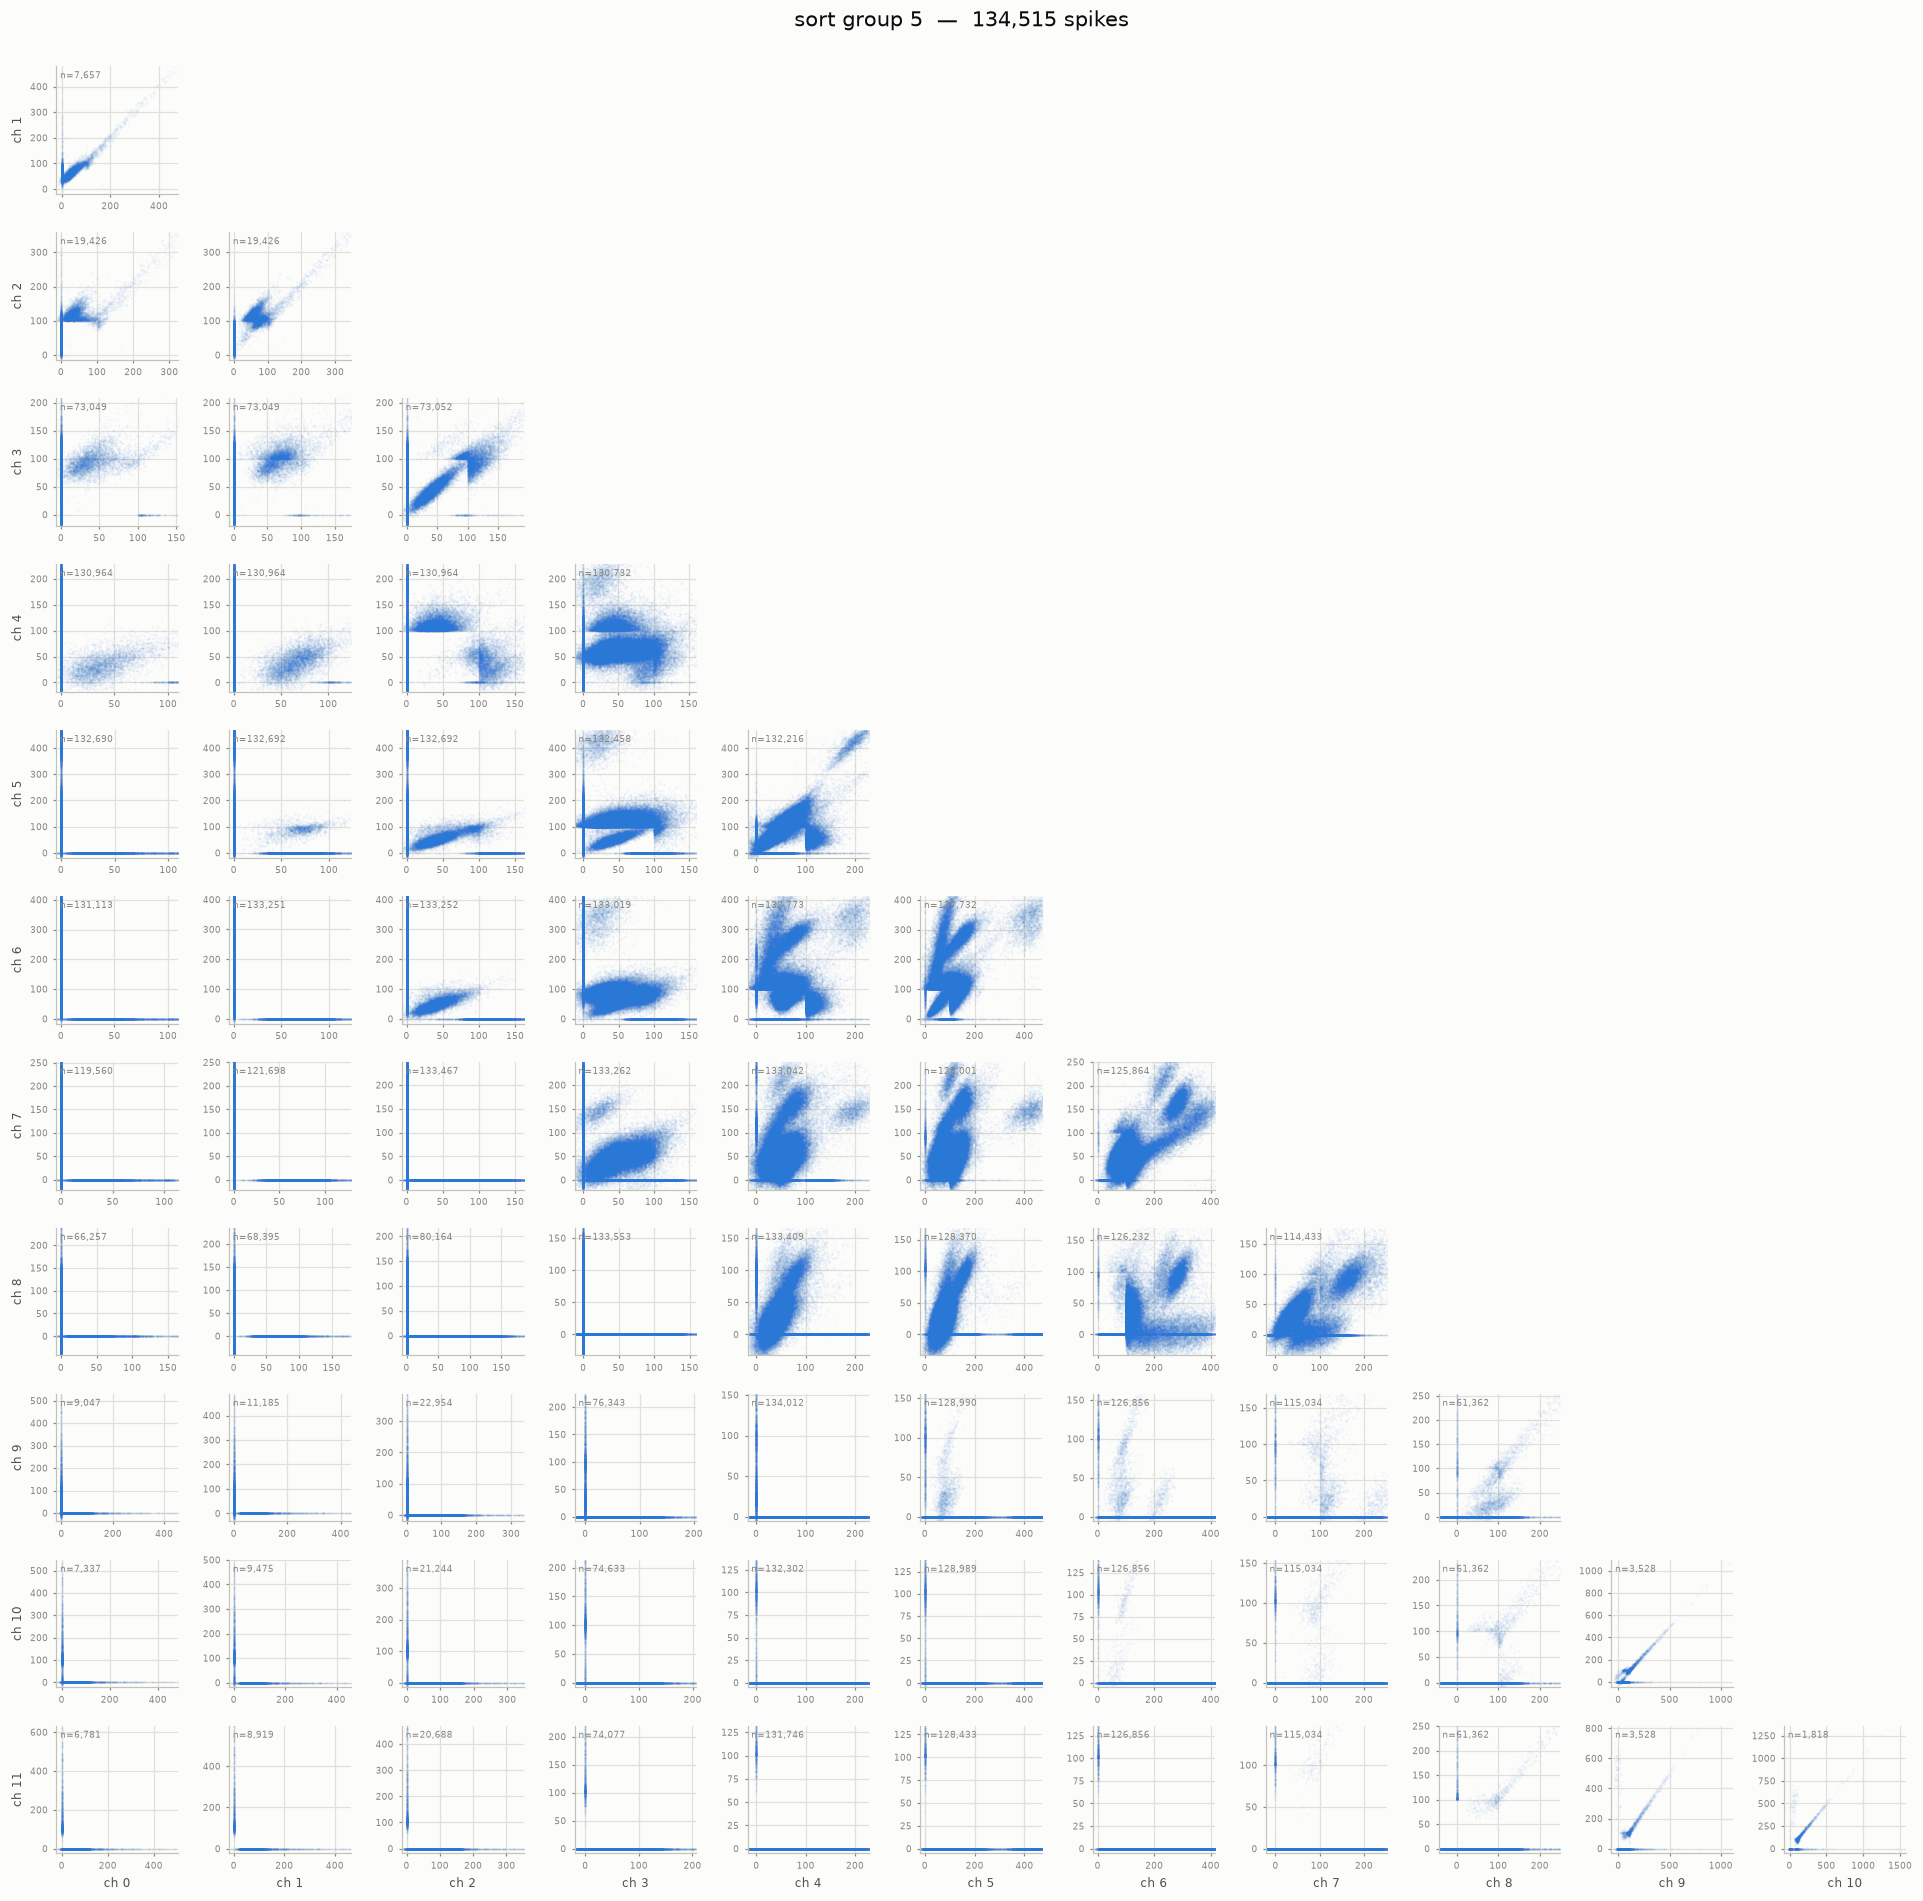

sort group 8: 34,806 spikes over 66 channel pairs.
  surviving the both-zero drop, per panel: min 1,400  median 30,445  max 34,223   (0 empty panel(s))
  outside the 99.5% view and therefore not drawn: 12,753 of 1,548,699 plotted points (0.82%)


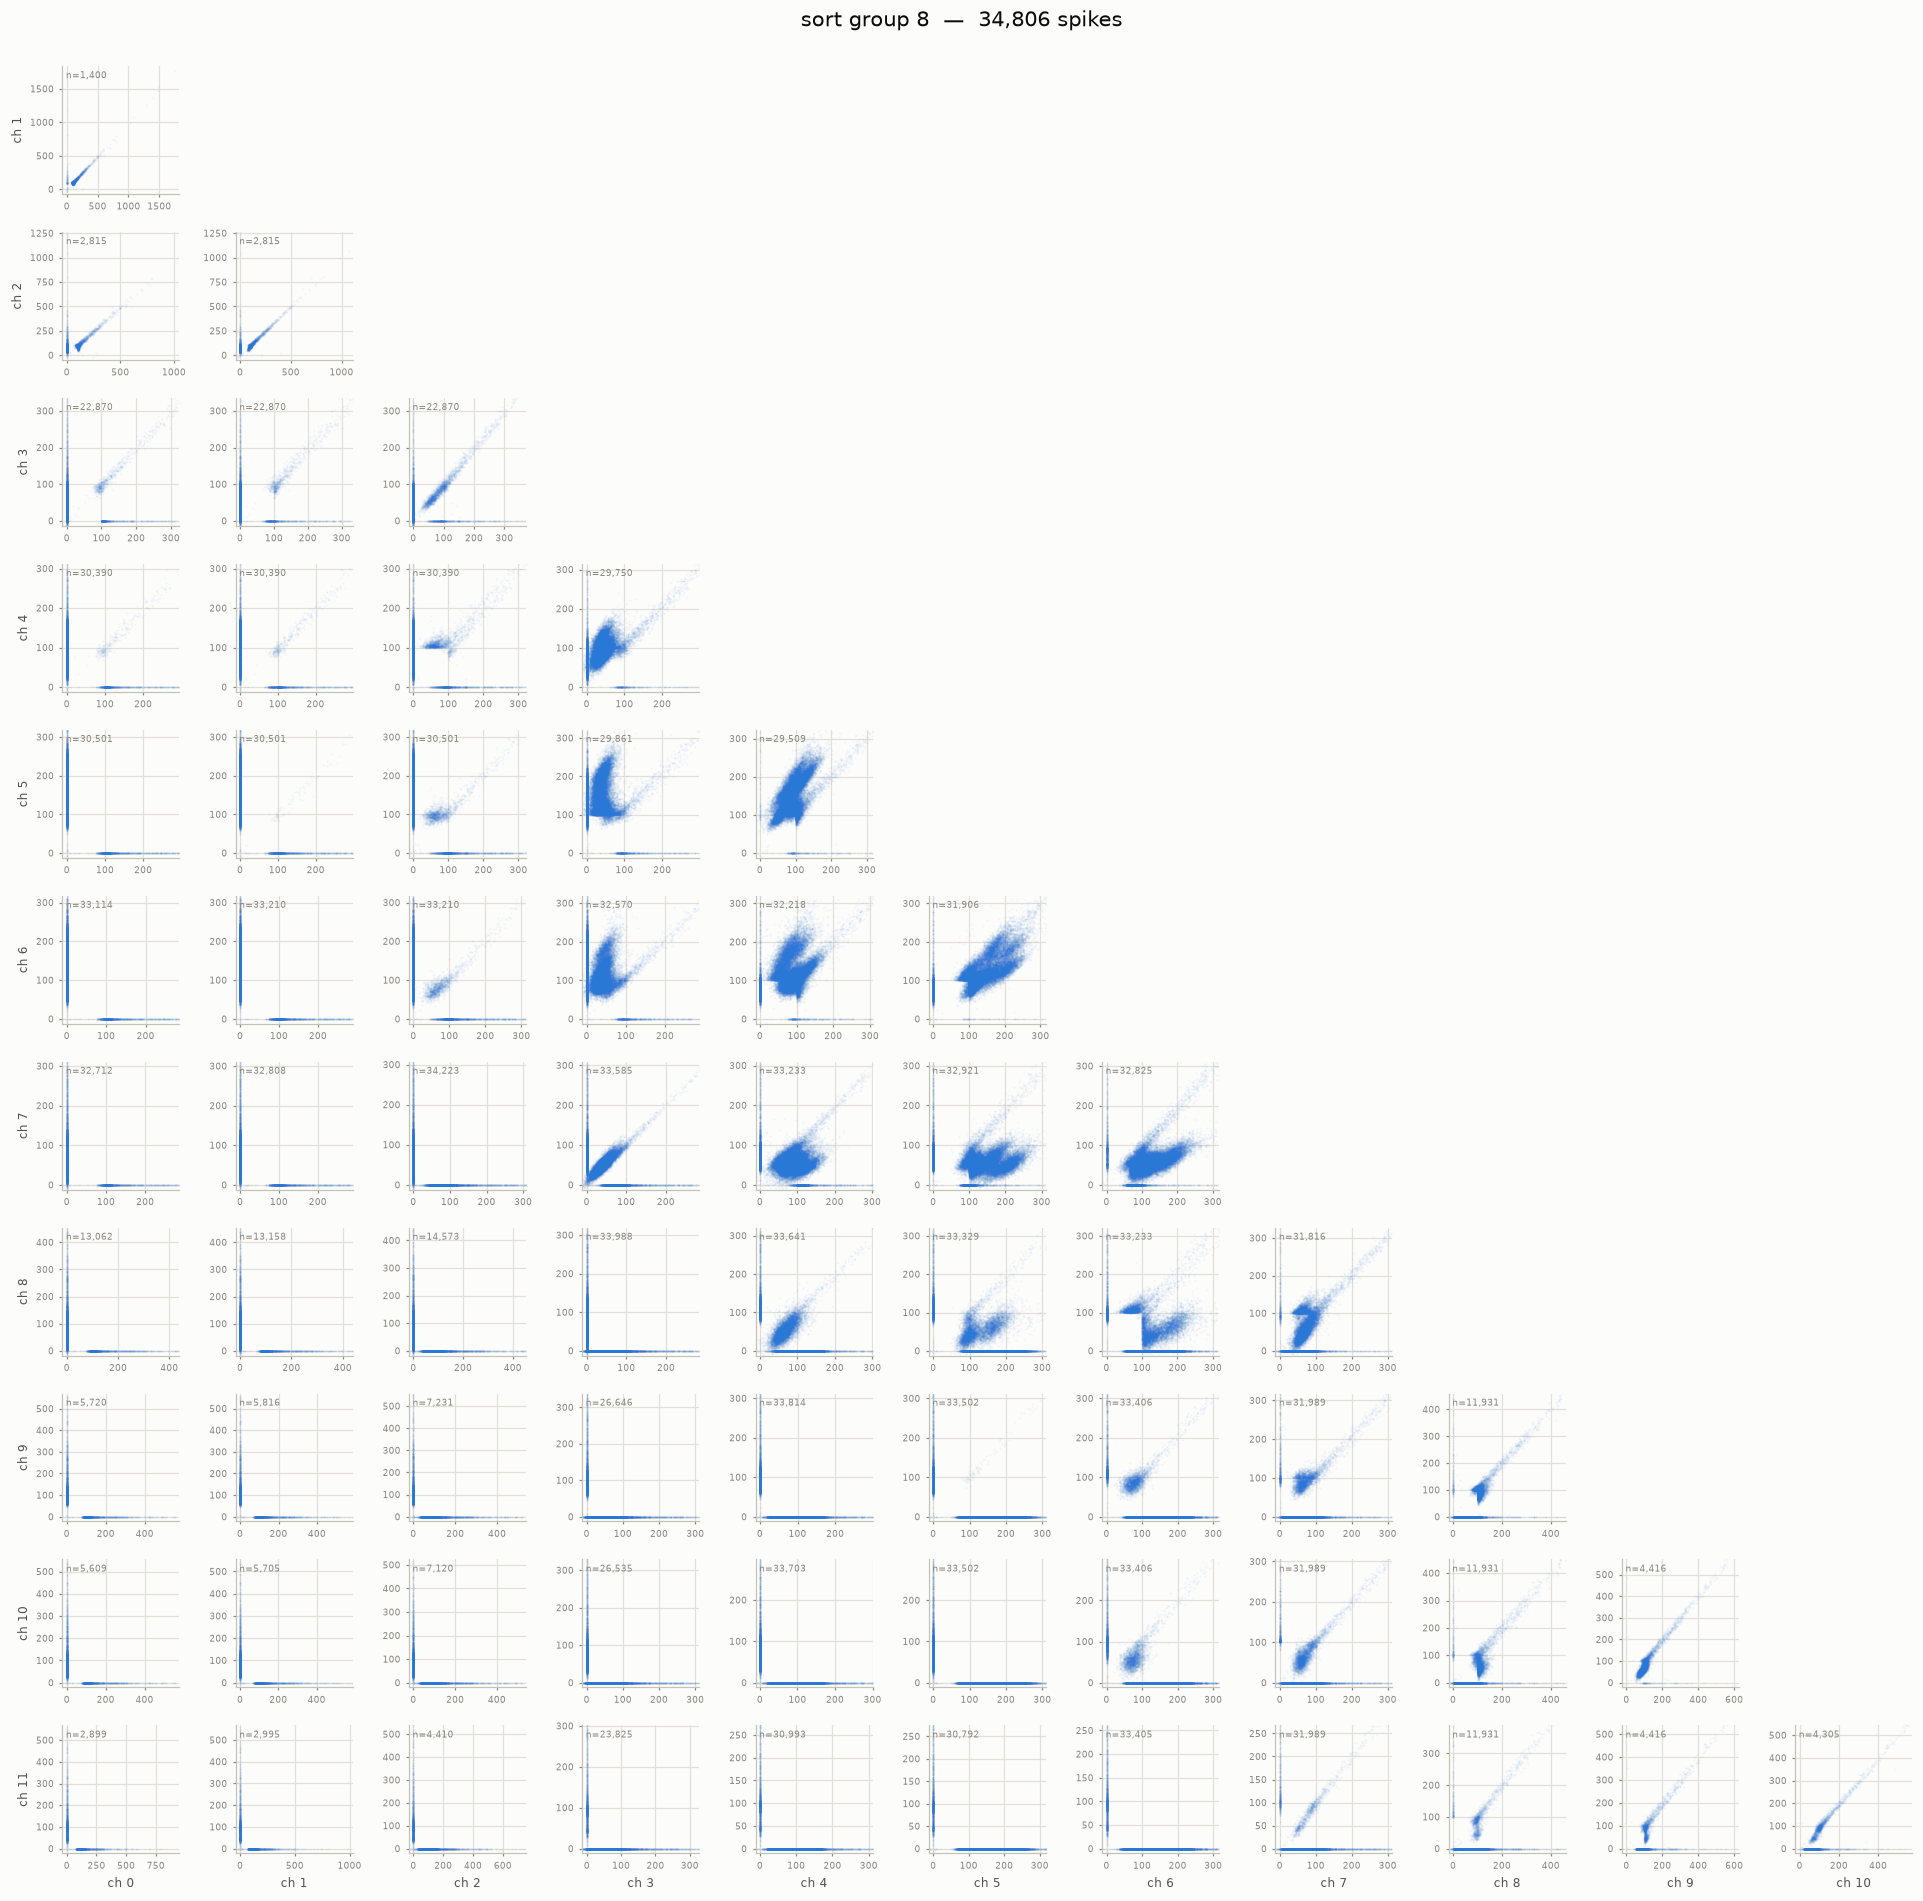

sort group 12: 122,439 spikes over 66 channel pairs.
  surviving the both-zero drop, per panel: min 1,300  median 98,217  max 121,651   (0 empty panel(s))
  outside the 99.5% view and therefore not drawn: 54,870 of 5,445,862 plotted points (1.01%)


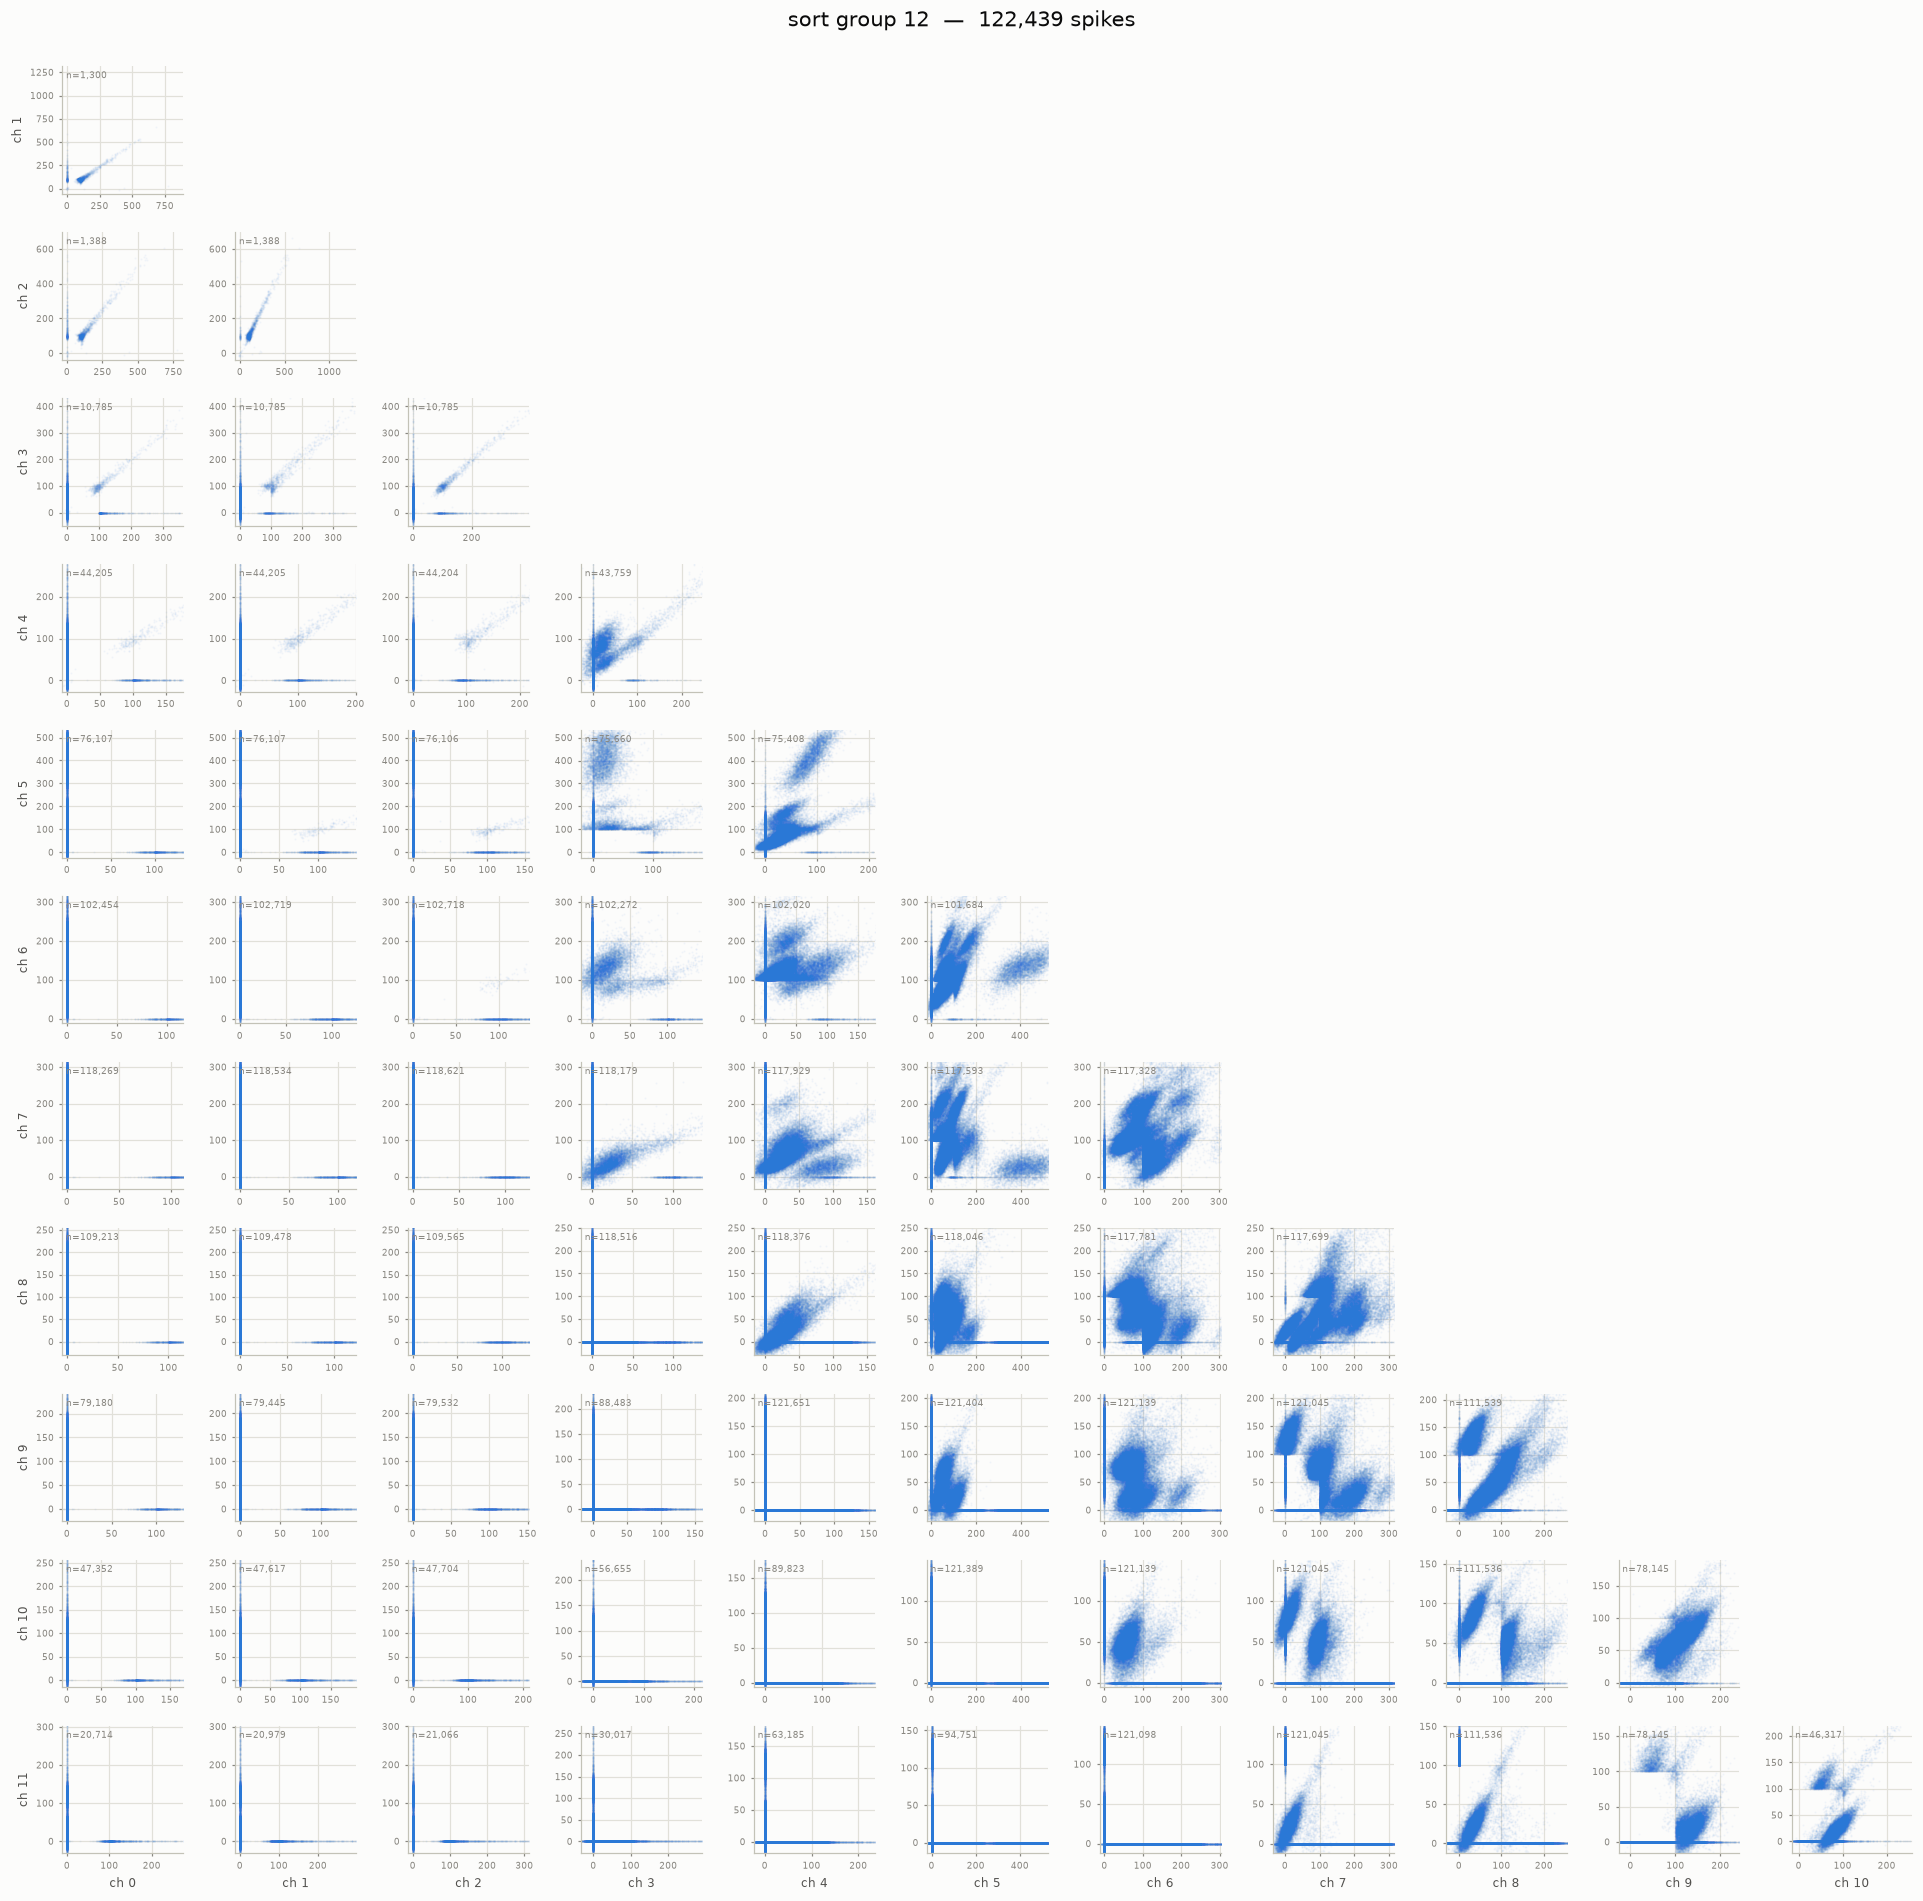

sort group 15: 141,839 spikes over 66 channel pairs.
  surviving the both-zero drop, per panel: min 2,480  median 138,189  max 140,612   (0 empty panel(s))
  outside the 99.5% view and therefore not drawn: 58,305 of 6,353,788 plotted points (0.92%)


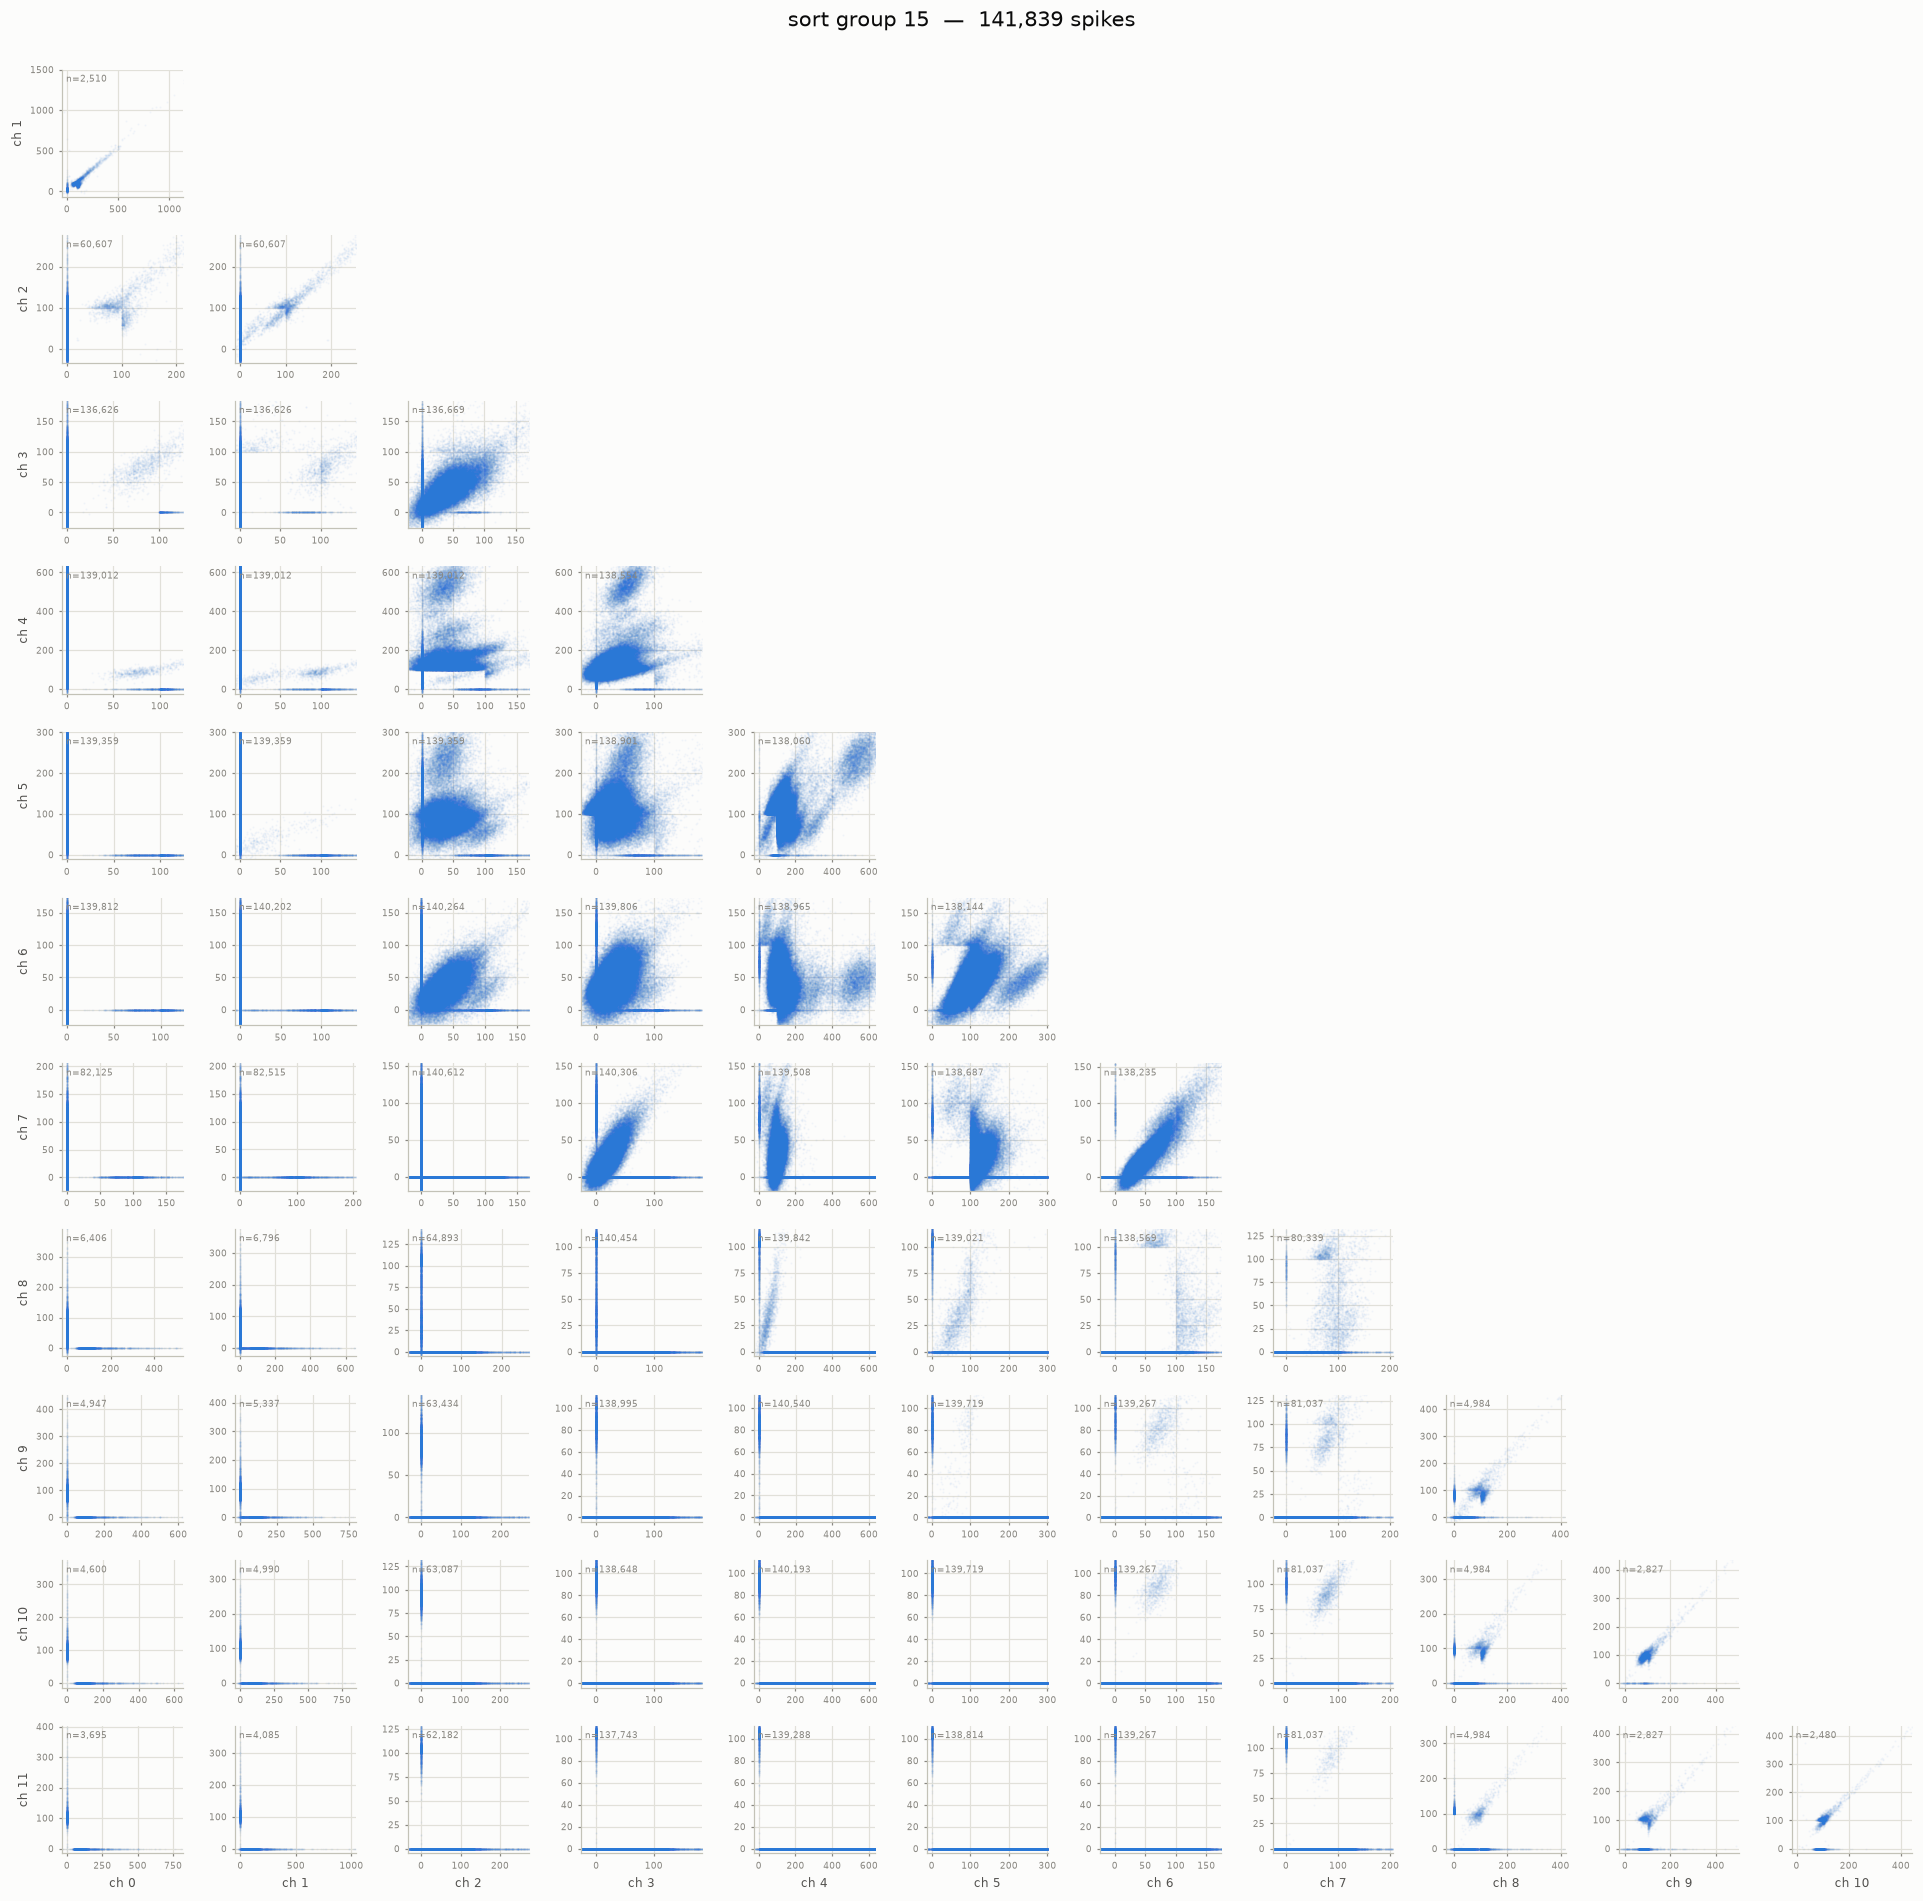

sort group 18: 81,105 spikes over 66 channel pairs.
  surviving the both-zero drop, per panel: min 4,632  median 69,490  max 80,442   (0 empty panel(s))
  outside the 99.5% view and therefore not drawn: 33,542 of 3,584,689 plotted points (0.94%)


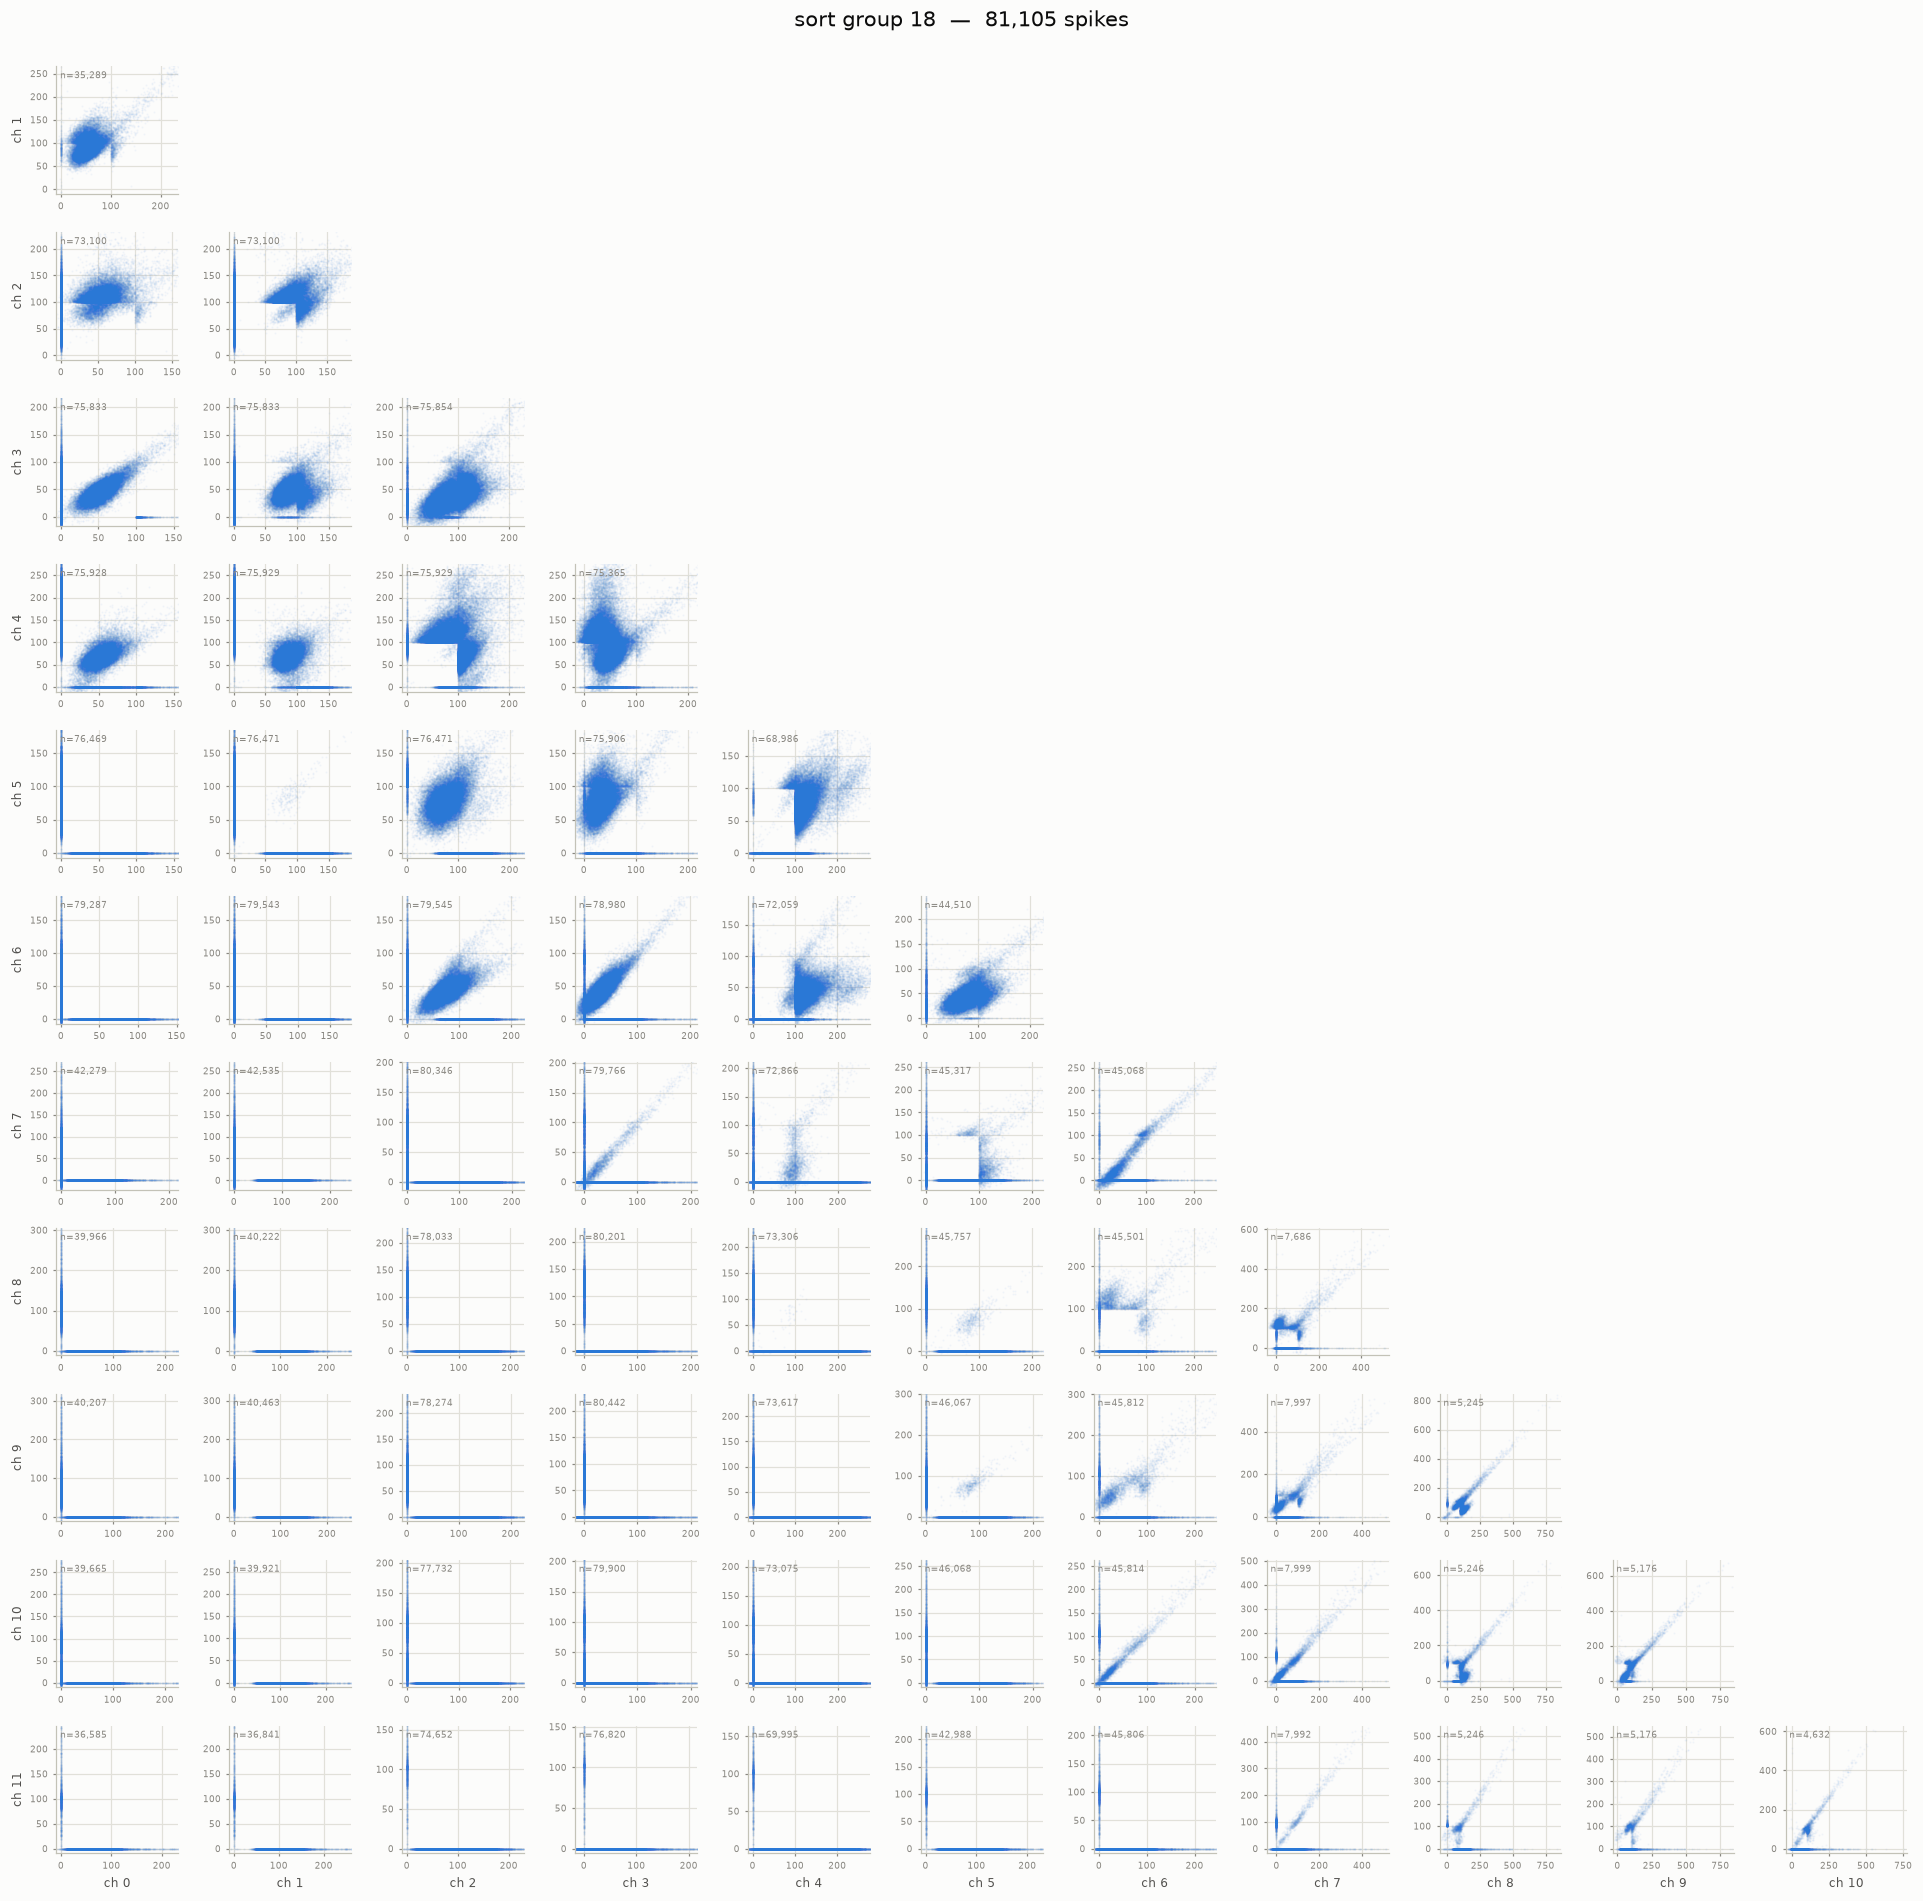

sort group 22: 52,073 spikes over 66 channel pairs.
  surviving the both-zero drop, per panel: min 746  median 49,826  max 51,688   (0 empty panel(s))
  outside the 99.5% view and therefore not drawn: 24,462 of 2,312,805 plotted points (1.06%)


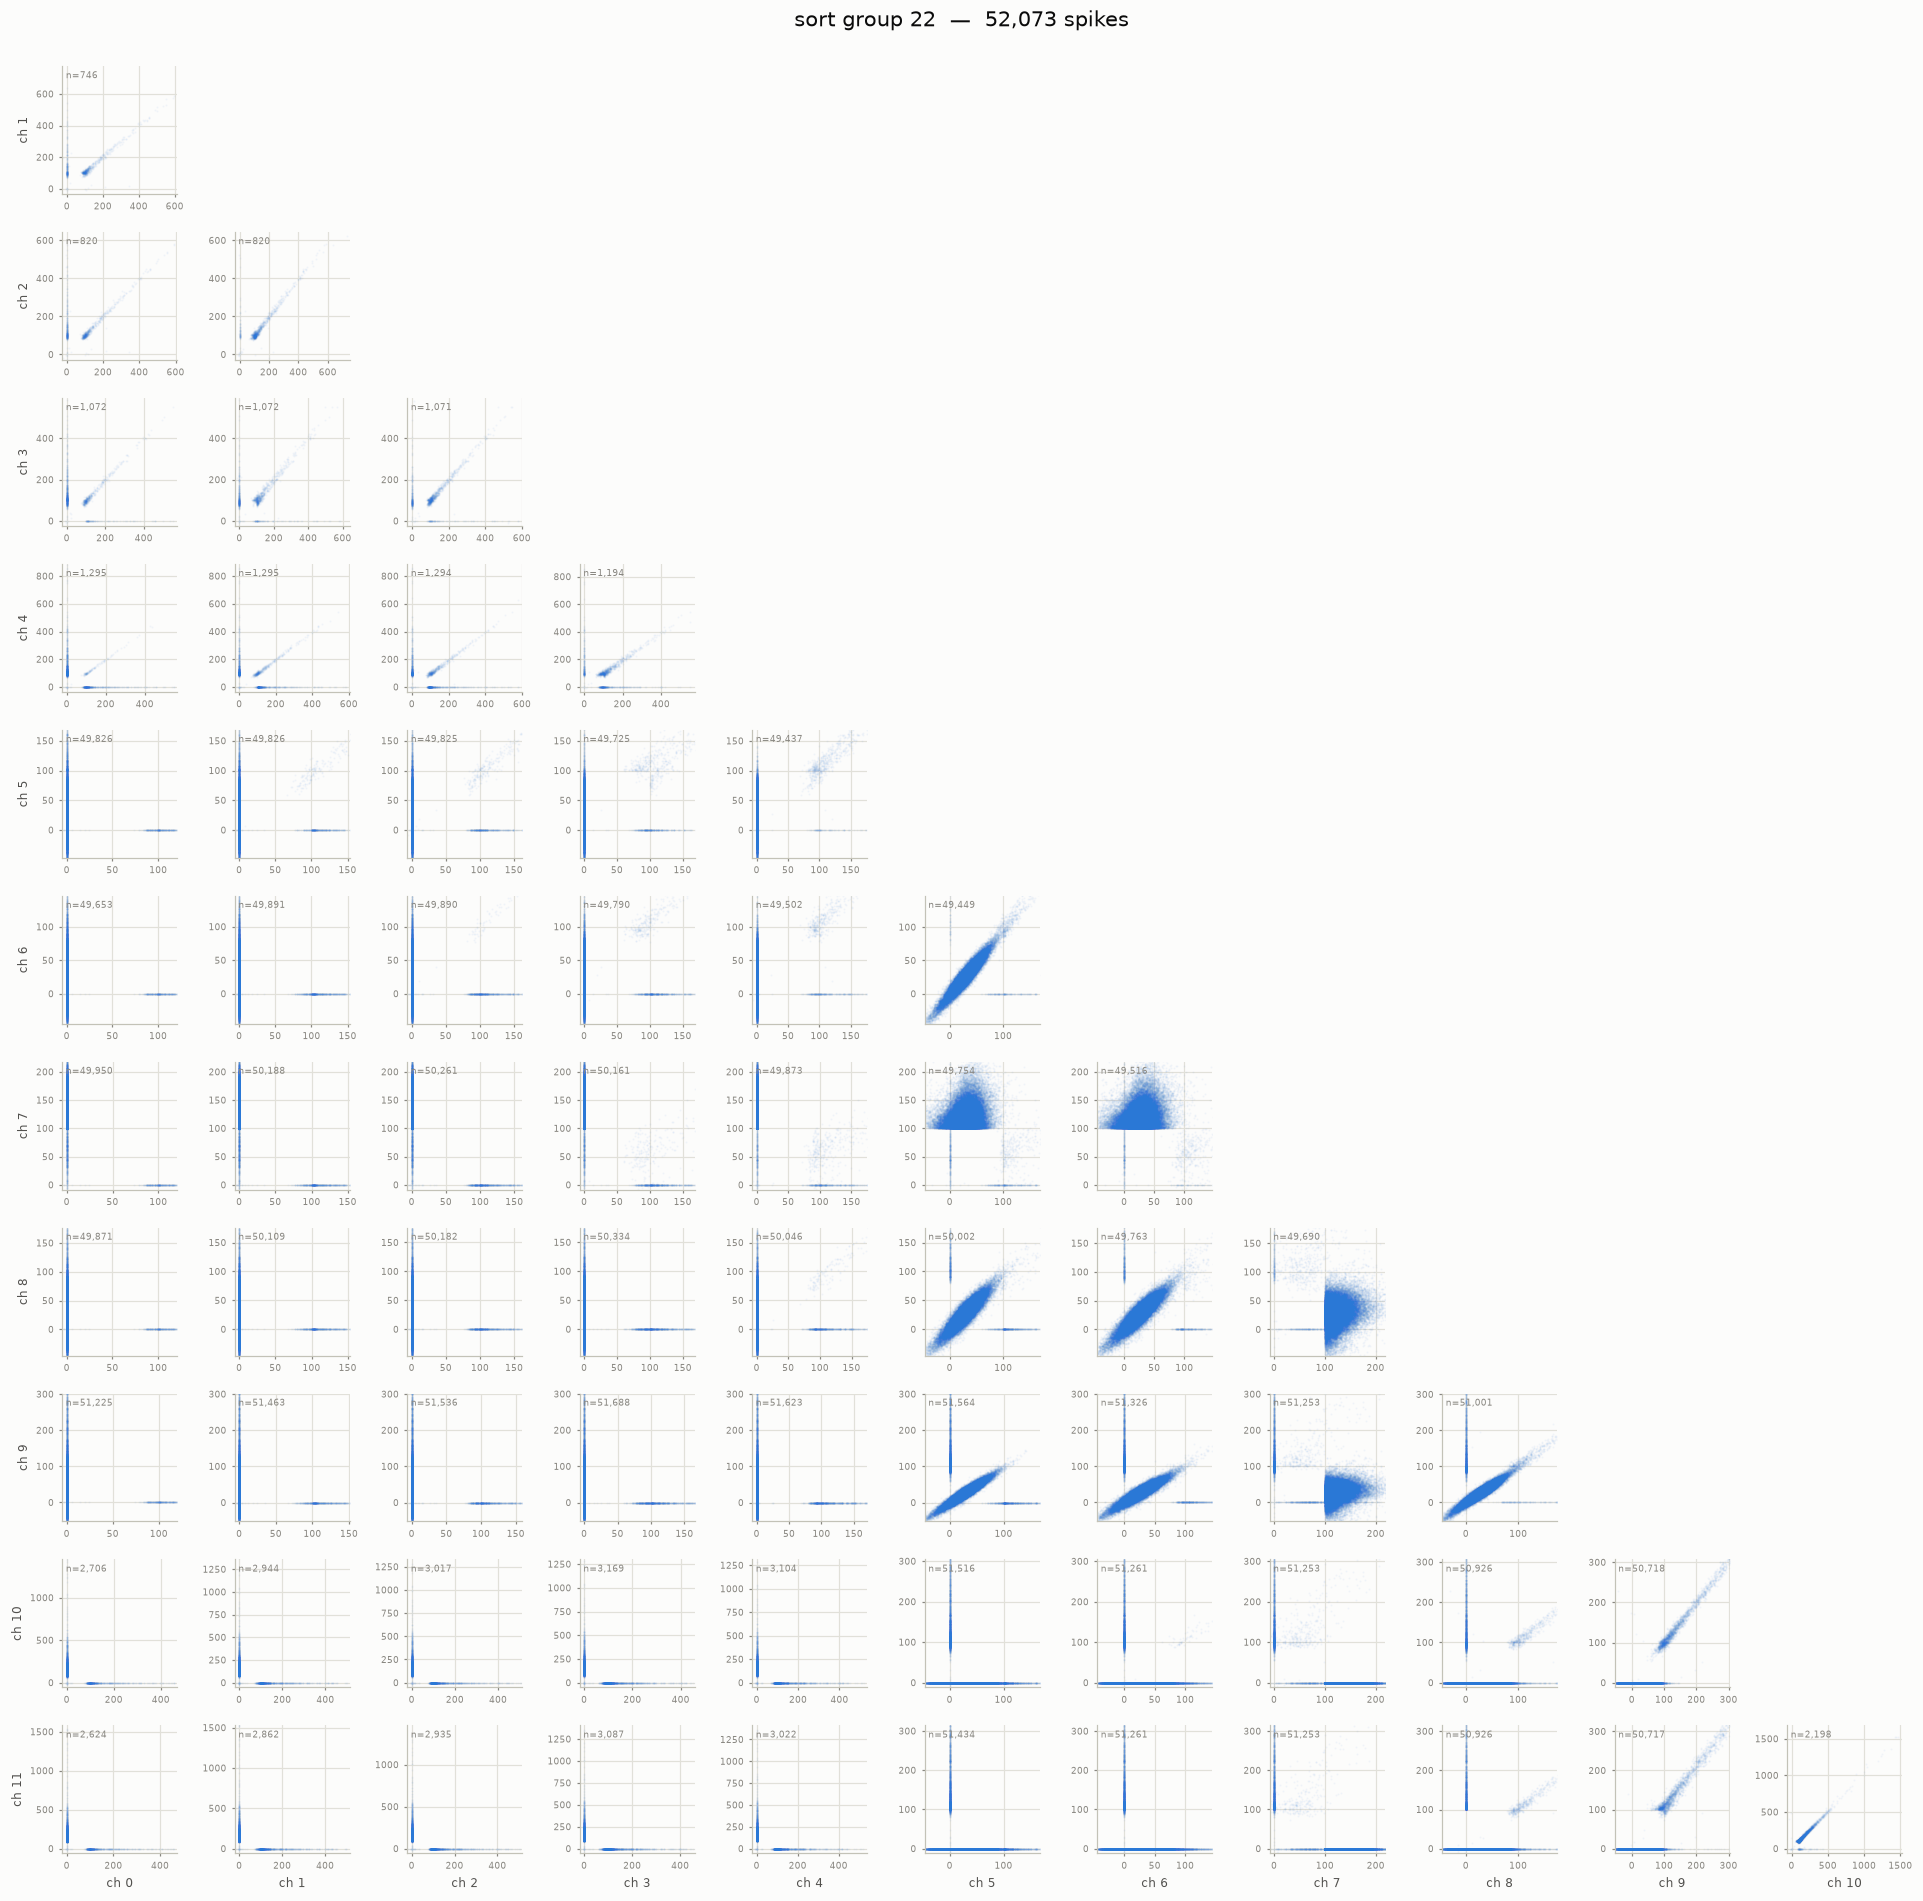

sort group 25: 8,881 spikes over 66 channel pairs.
  surviving the both-zero drop, per panel: min 2,328  median 6,223  max 8,435   (0 empty panel(s))
  outside the 99.5% view and therefore not drawn: 3,263 of 377,295 plotted points (0.86%)


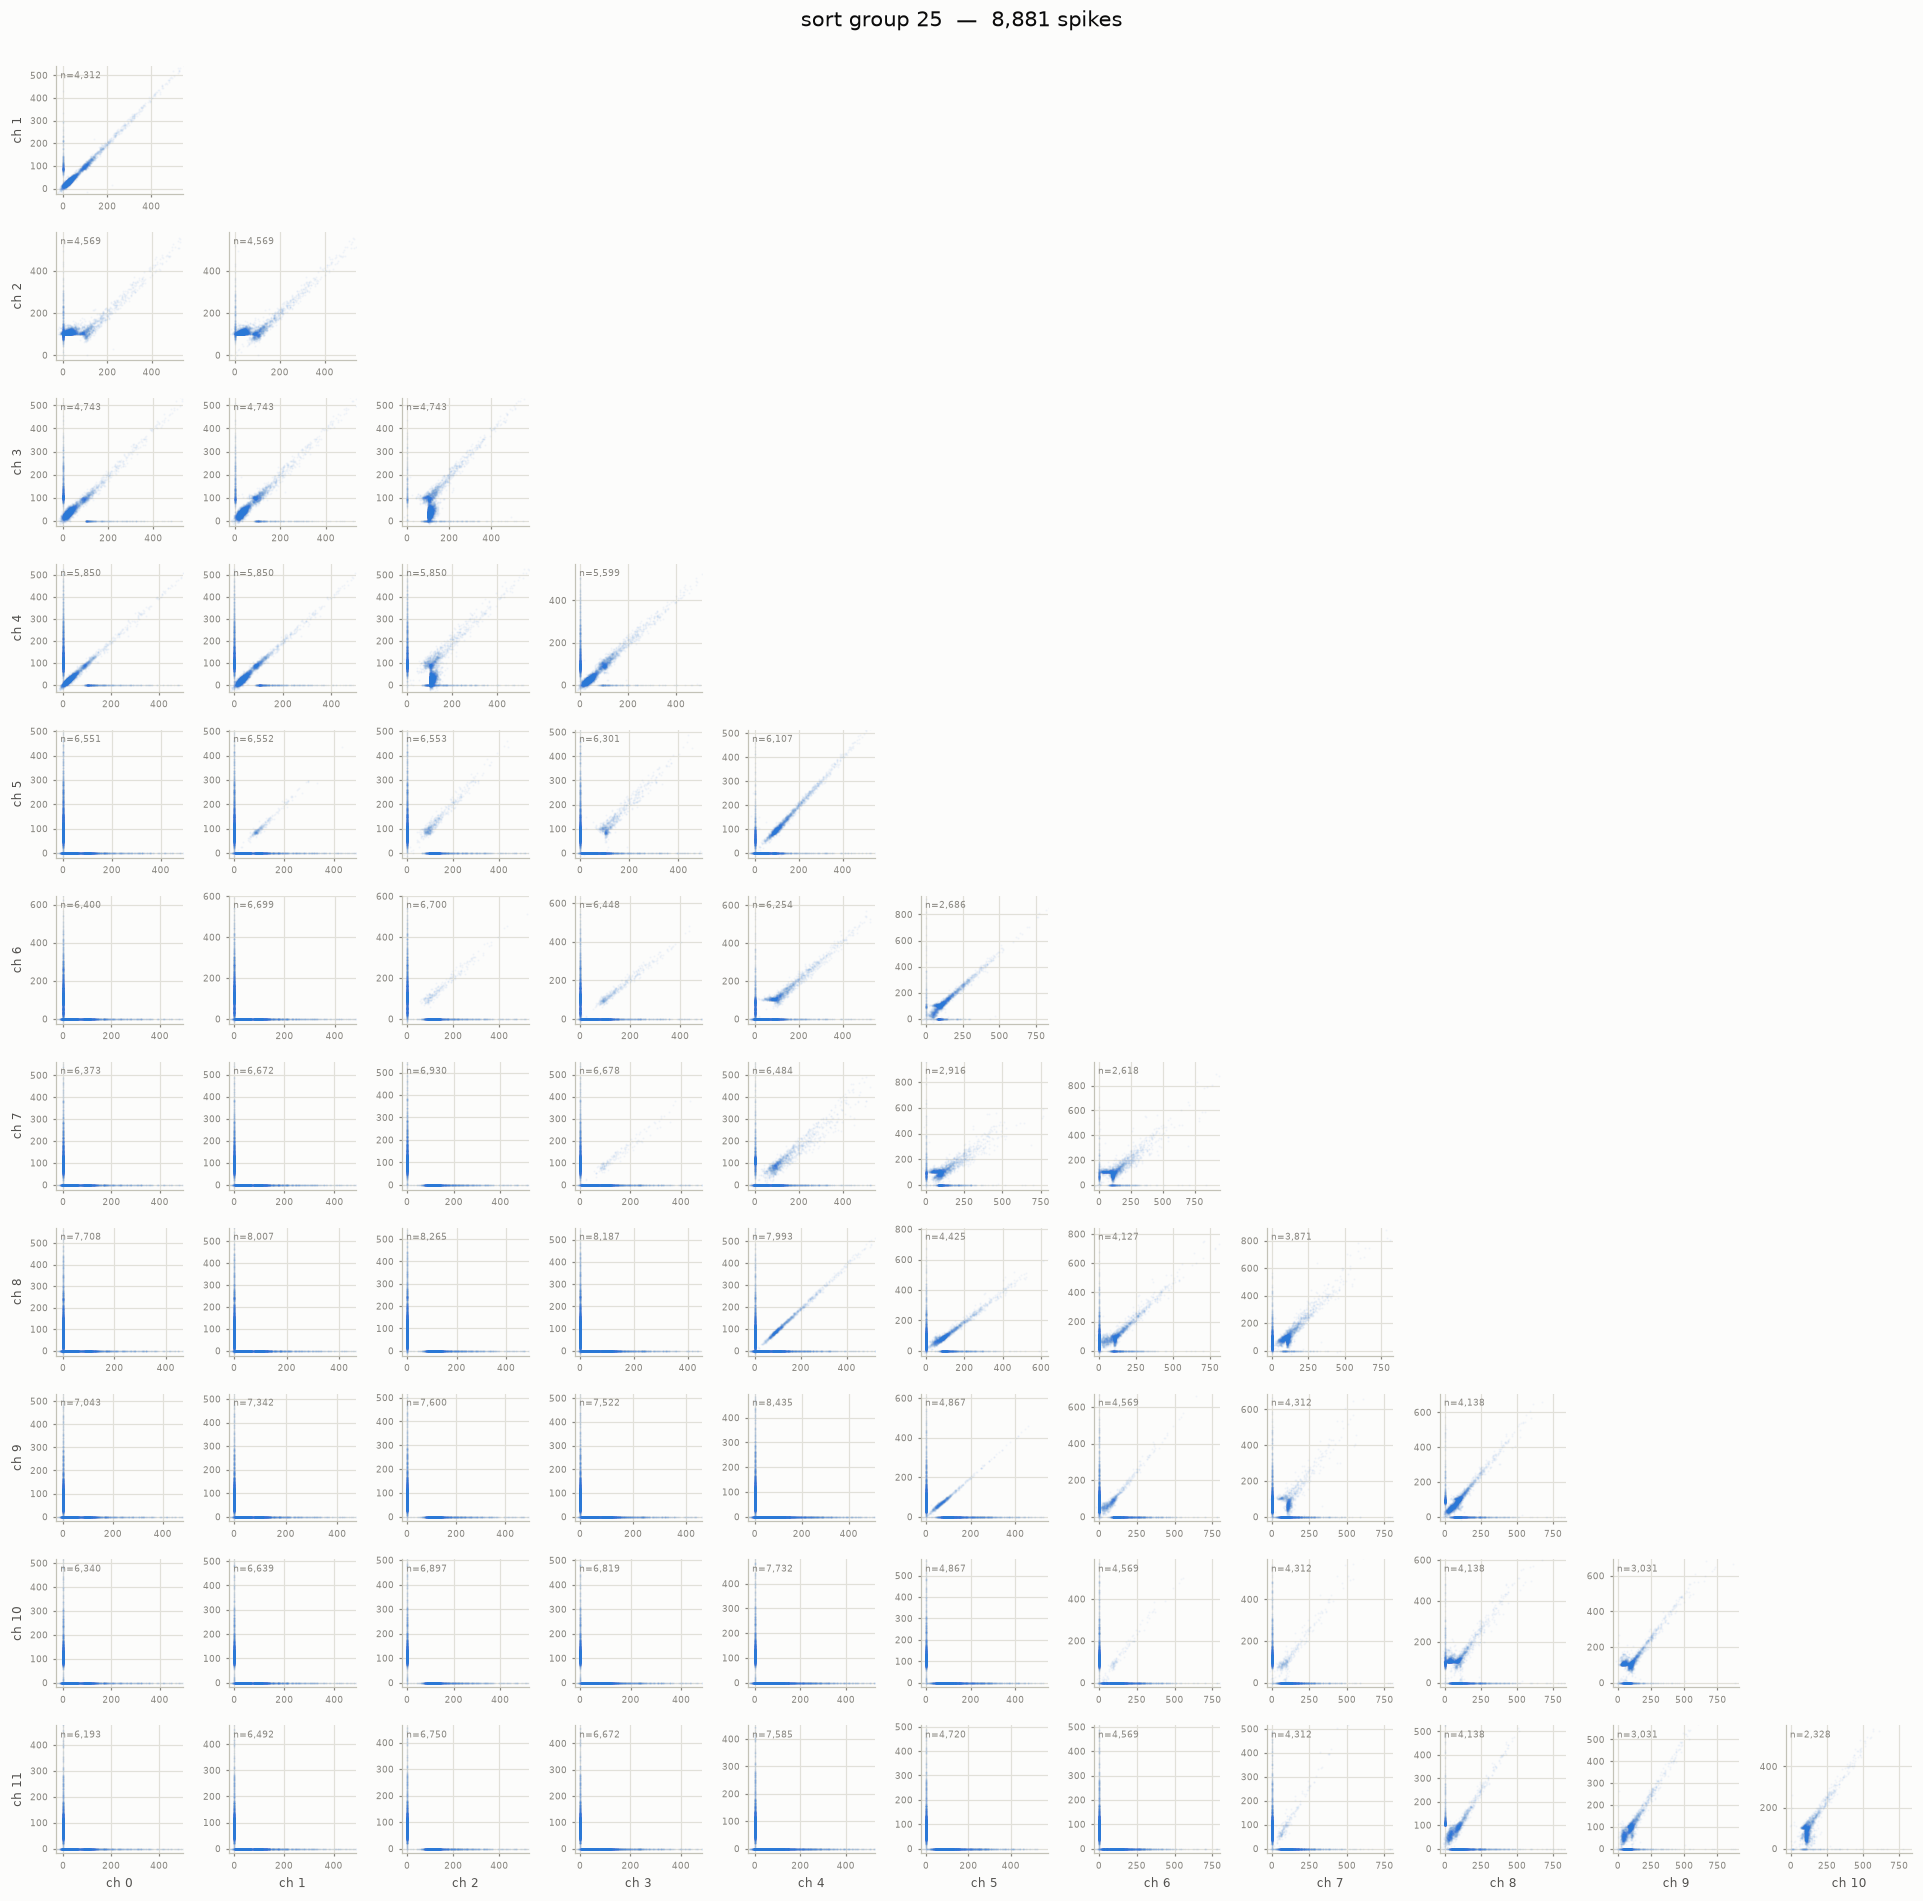

sort group 28: 81,667 spikes over 66 channel pairs.
  surviving the both-zero drop, per panel: min 1,248  median 74,803  max 81,228   (0 empty panel(s))
  outside the 99.5% view and therefore not drawn: 43,810 of 3,662,540 plotted points (1.20%)


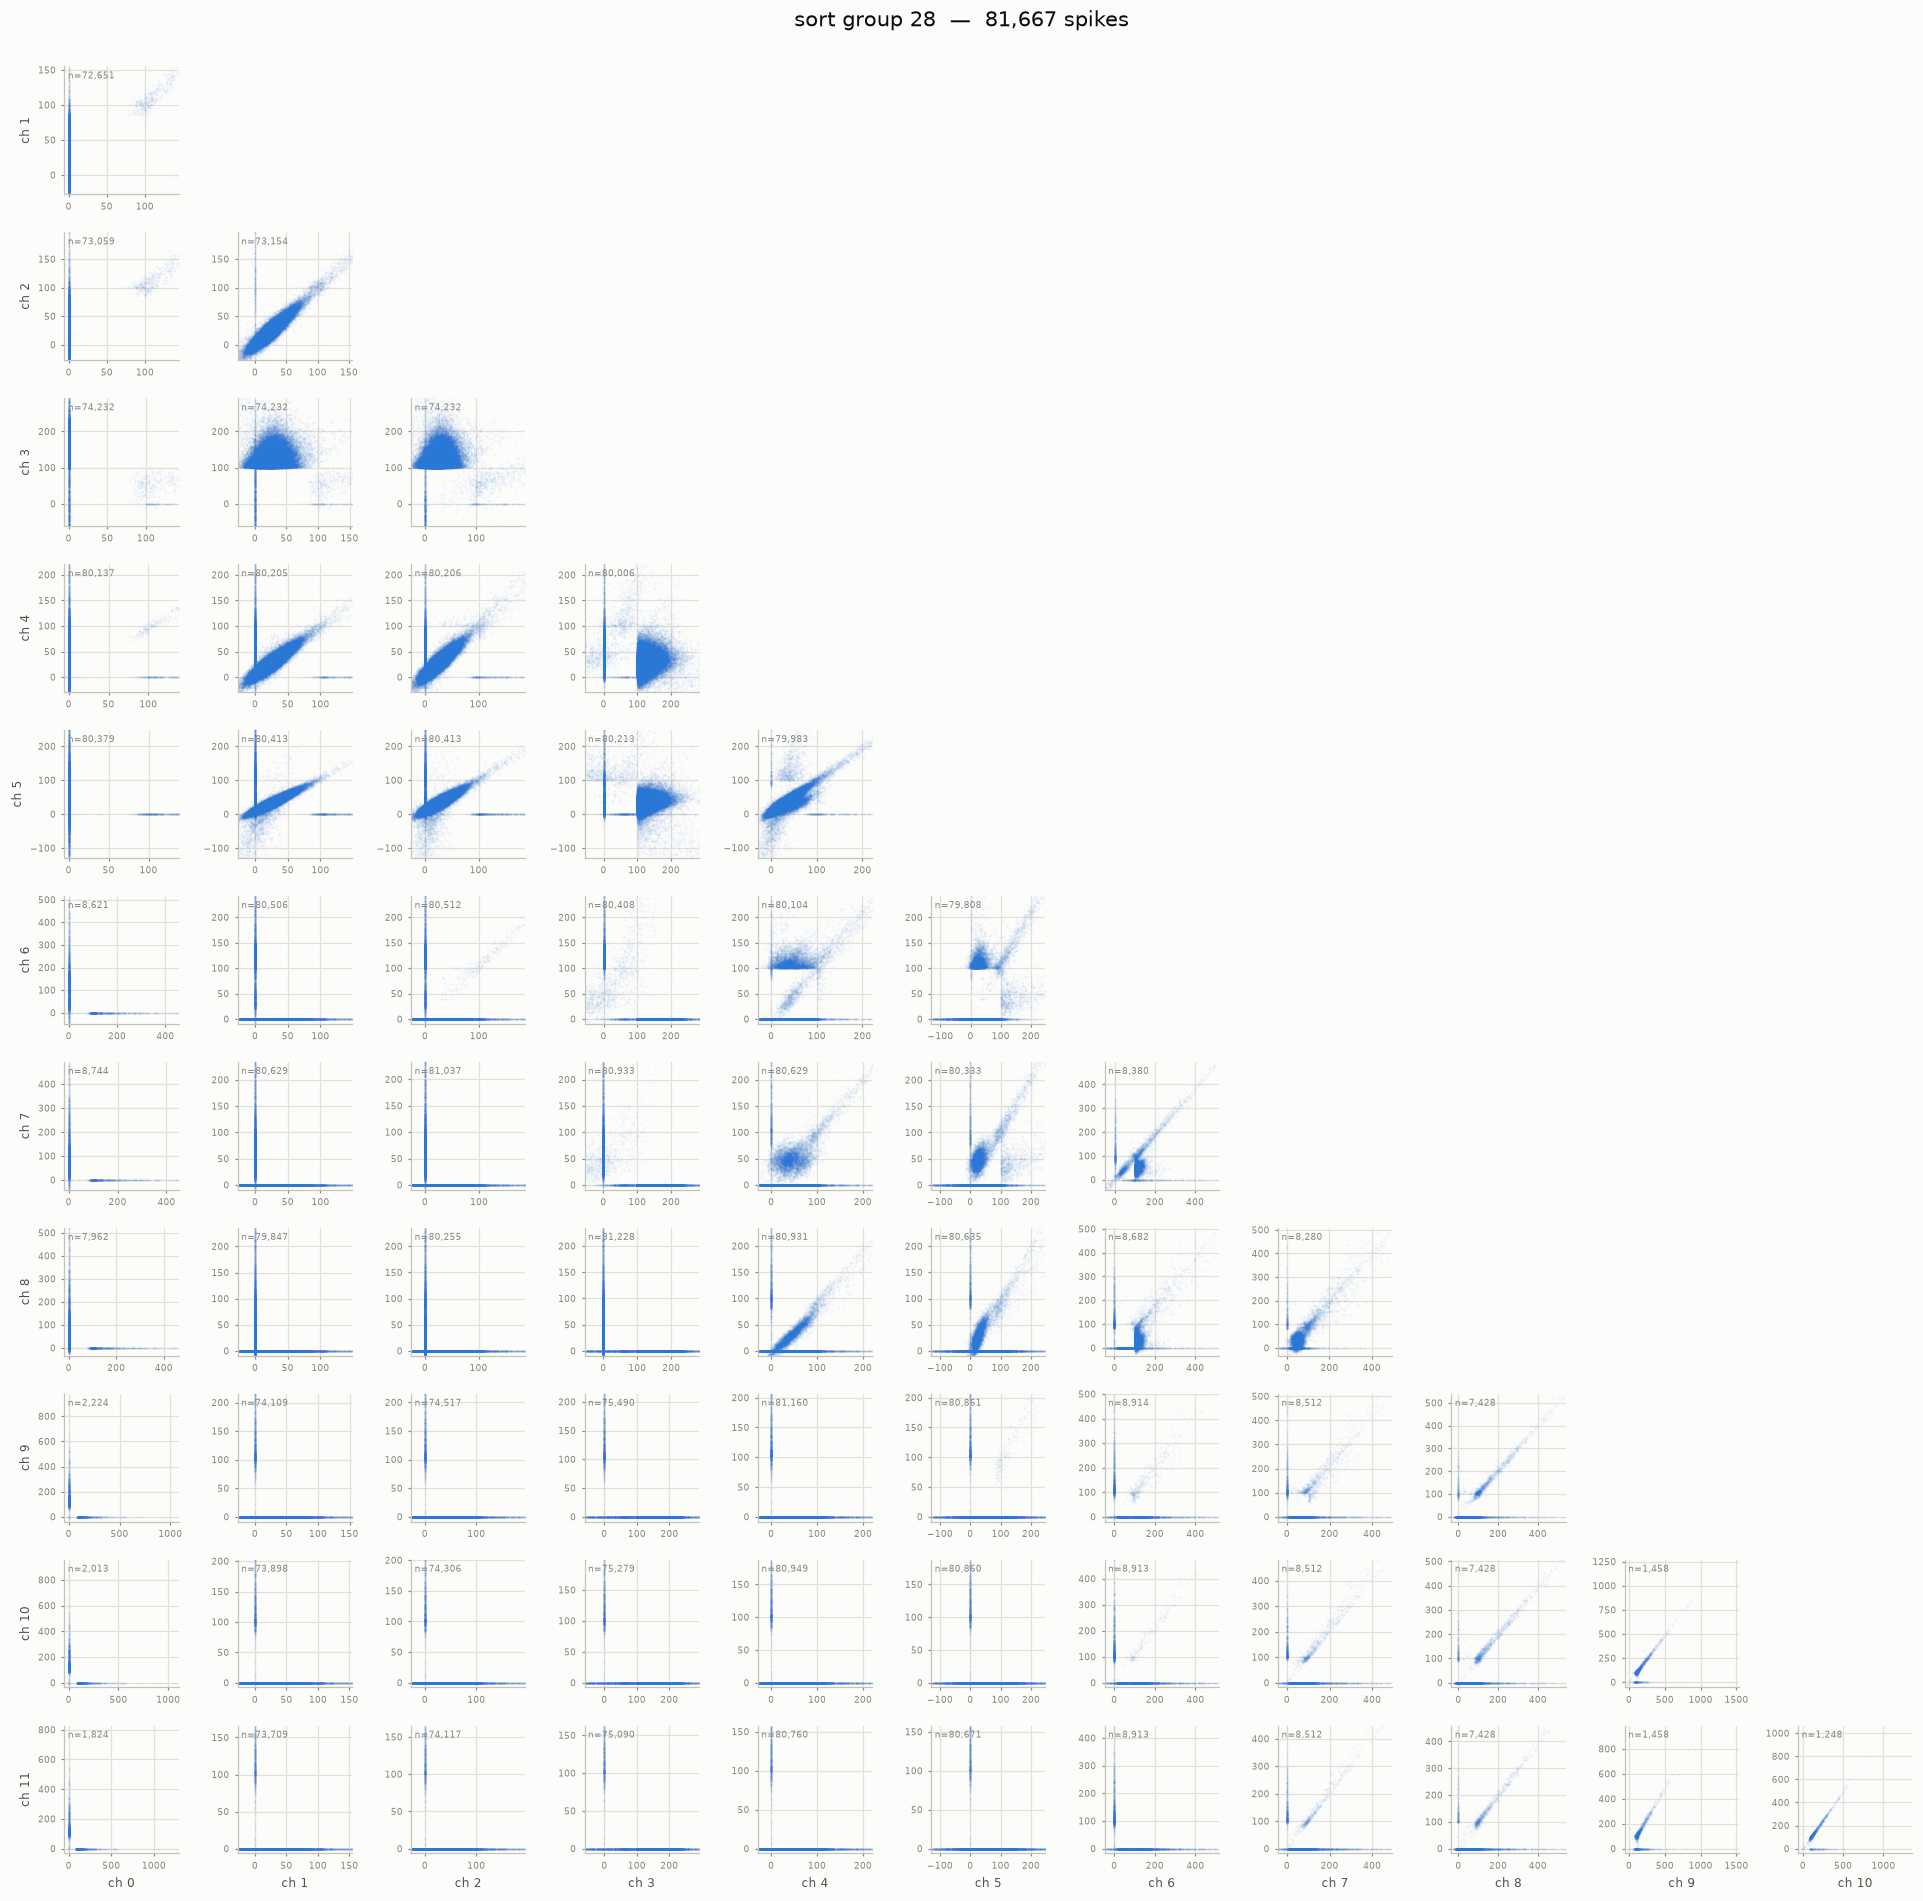

sort group 31: 27,562 spikes over 66 channel pairs.
  surviving the both-zero drop, per panel: min 2,597  median 15,027  max 27,318   (0 empty panel(s))
  outside the 99.5% view and therefore not drawn: 10,334 of 1,207,032 plotted points (0.86%)


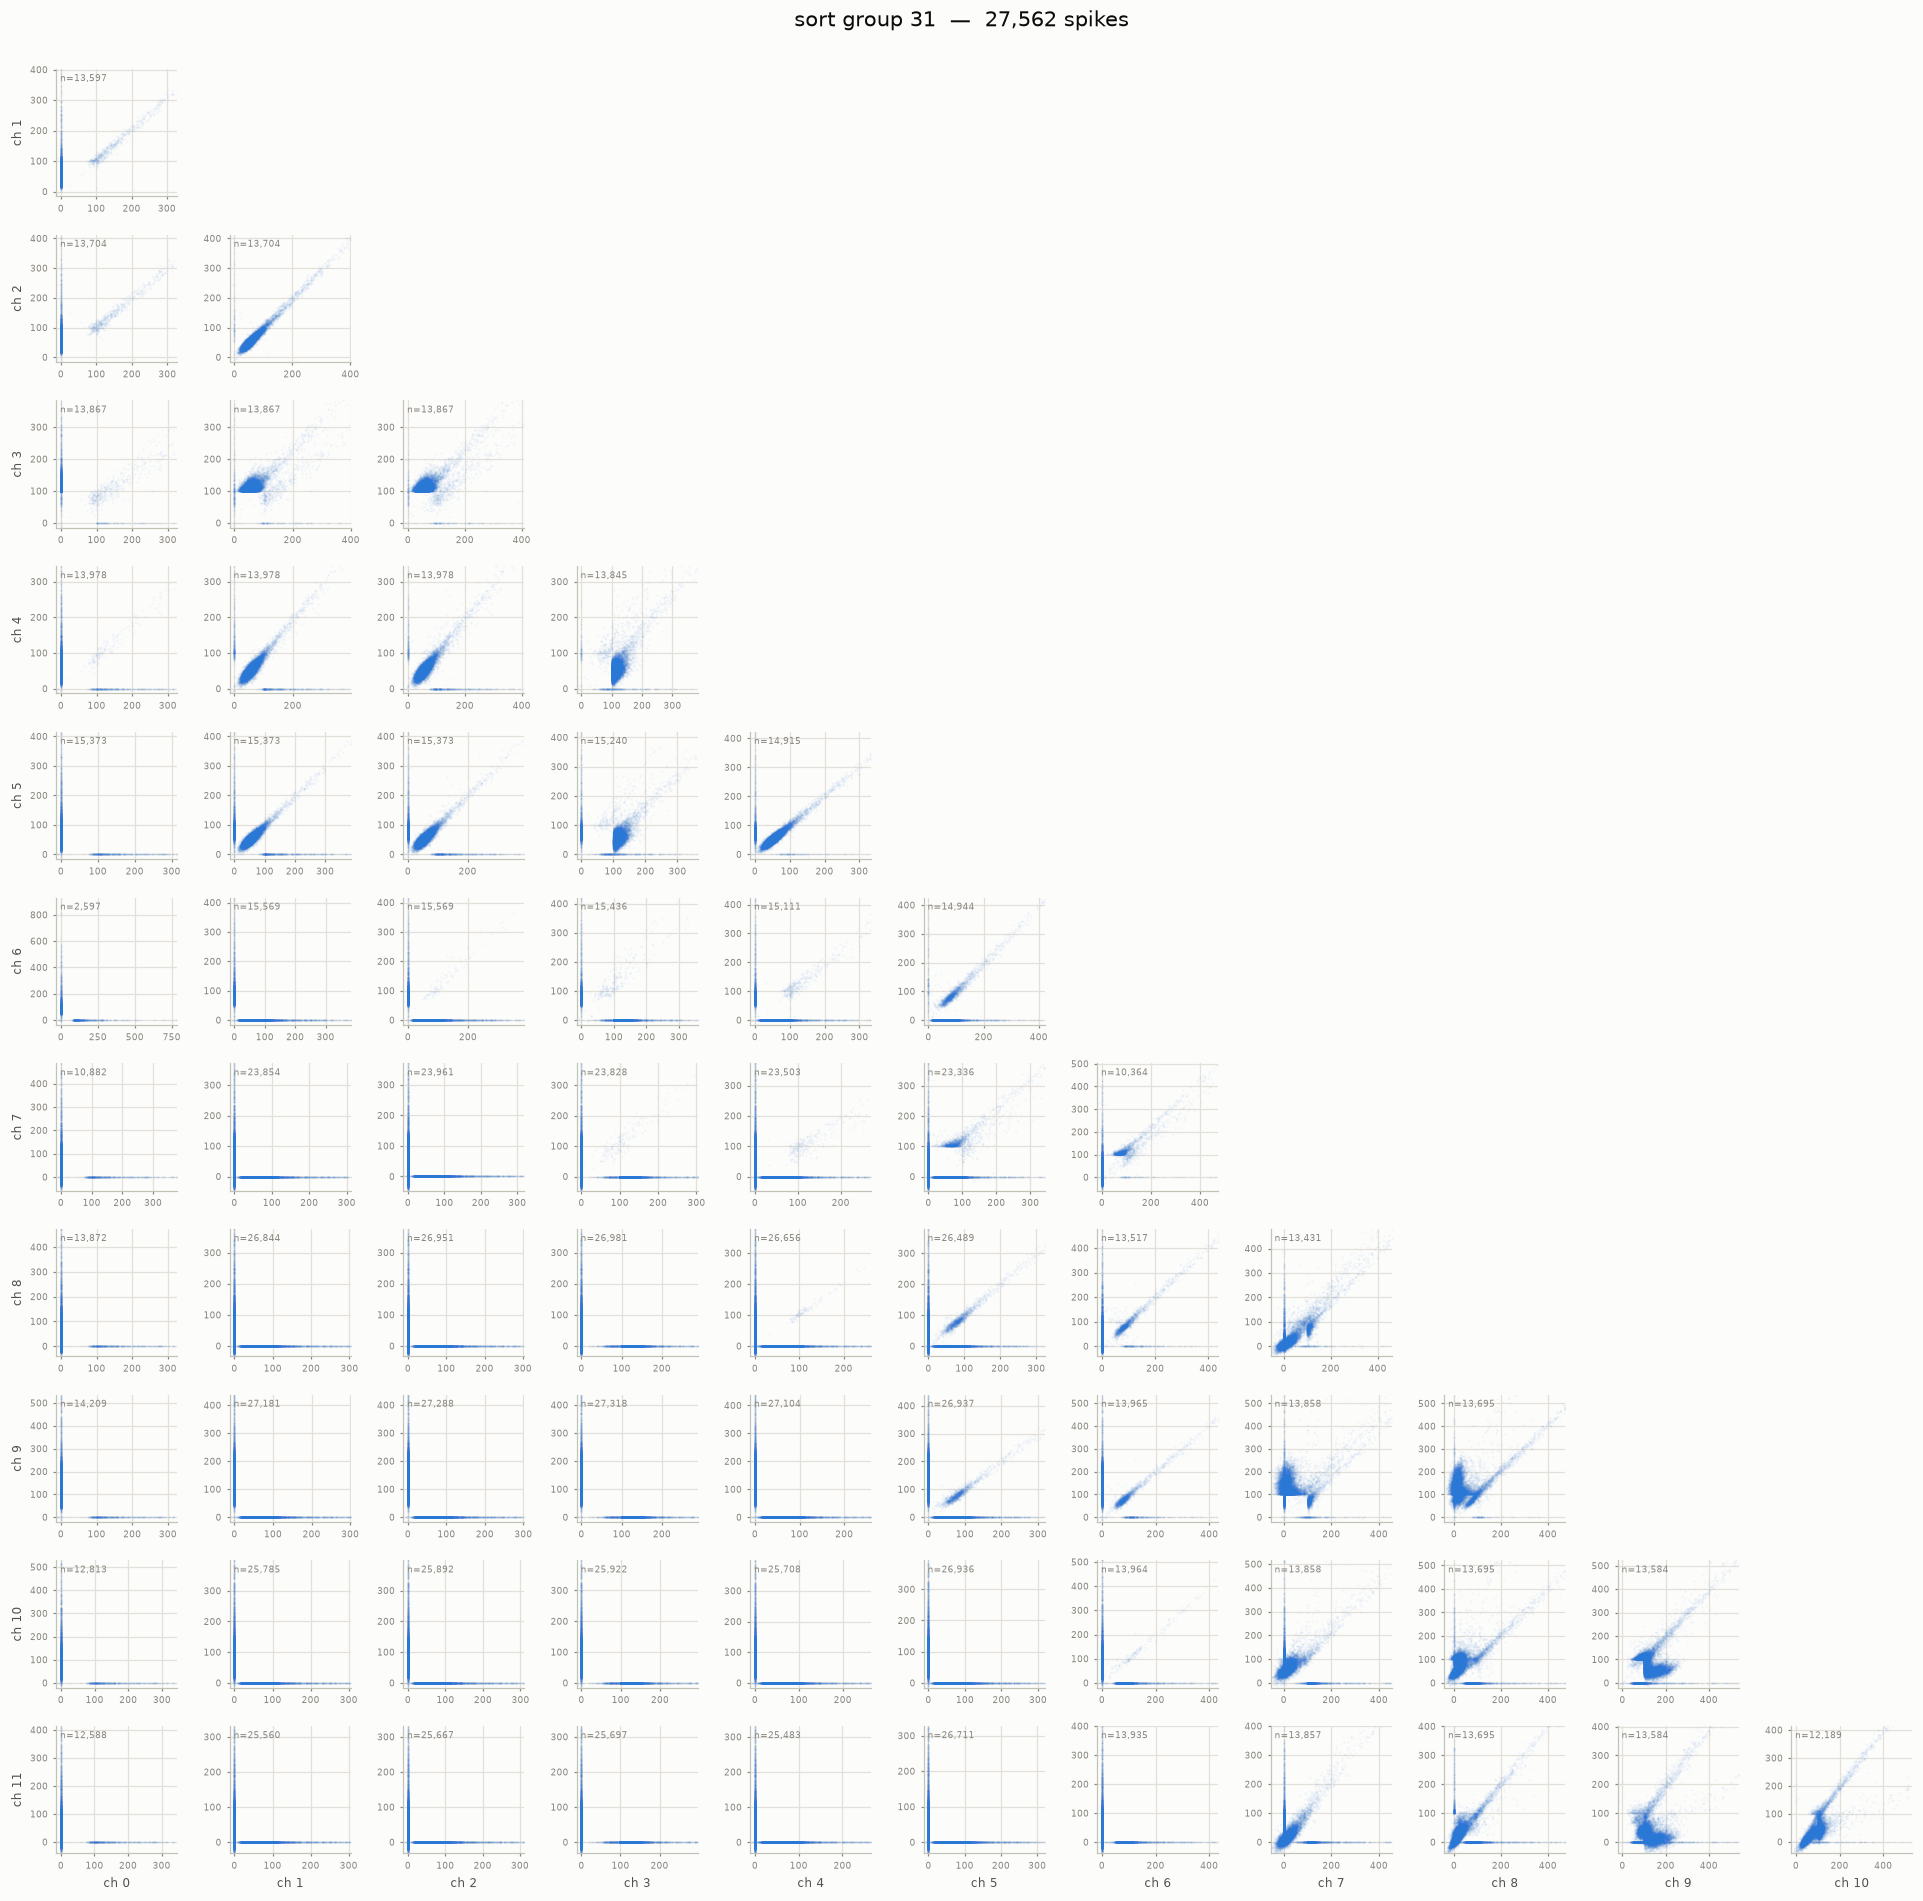

In [5]:
for g in SORT_GROUPS:
    fig = plot_sort_group(g, spikes, MARK_COLS)
    plt.show()
    plt.close(fig)

## 5. Reading the result

What a healthy sort group looks like:

- Adjacent channel pairs (`ch 3` vs `ch 4`, say) show a fan of points spreading out from
  the origin, often with a few distinguishable arms. Each arm is a putative unit.
- The fan should reach well past the spike threshold (`encoder.spk_amp` in the config),
  not hug the origin.
- Far-apart channel pairs (`ch 0` vs `ch 11`) should be nearly empty — that is the
  distance-2 rule, not a problem.

What should make you suspicious:

- A channel that is exactly 0 in essentially every panel it appears in. Either it is a
  dead channel, or it is listed in `encoder.dead_channels`, or the sort group has fewer
  real channels than `mark_dim` and the tail is padding.
- Amplitudes that are all tiny, or clipped flat at one value.
- A blob that sits at a completely different place from the equivalent spyglass panel —
  that is the actual thing this notebook is checking for.

In [6]:
# per-channel occupancy: fraction of a sort group's spikes where that channel is exactly 0.
# A column of ~1.00 all the way down means that channel never carries signal.
occ = (spikes.groupby('elec_grp_id')[MARK_COLS]
             .apply(lambda g: (g == 0).mean())
             .round(2))
occ.columns = [c.replace('mark_dim_', 'ch ') for c in occ.columns]
occ

,ch 0,ch 1,ch 2,ch 3,ch 4,ch 5,ch 6,ch 7,ch 8,ch 9,ch 10,ch 11
elec_grp_id,,,,,,,,,,,,
2,0.99,0.98,0.73,0.11,0.10,0.08,0.03,0.28,0.89,0.91,0.93,0.99
5,0.96,0.94,0.86,0.46,0.03,0.05,0.07,0.15,0.55,0.97,0.99,0.99
8,0.96,0.96,0.92,0.36,0.16,0.16,0.09,0.10,0.66,0.87,0.88,0.95
12,0.99,0.99,0.99,0.92,0.64,0.39,0.17,0.04,0.12,0.36,0.62,0.84
15,0.99,0.98,0.57,0.04,0.03,0.03,0.03,0.44,0.97,0.98,0.98,0.99
18,0.57,0.56,0.10,0.07,0.16,0.49,0.45,0.91,0.94,0.94,0.94,0.98
22,0.99,0.99,0.98,0.98,0.98,0.05,0.06,0.05,0.05,0.03,0.96,0.96
25,0.55,0.51,0.49,0.49,0.39,0.71,0.73,0.73,0.58,0.66,0.74,0.75
28,0.99,0.11,0.11,0.09,0.02,0.03,0.90,0.90,0.91,0.98,0.98,0.99


## 6. The same plot, in 10-minute windows, written to PDF

Section 4 pools the whole session into one figure per sort group. This section cuts the
session into consecutive `WINDOW_MIN`-minute windows and draws the same lower-triangle
grid once per window, so you can see whether the clusters hold still, drift, appear or
vanish over the course of the recording.

Nothing is shown inline — with 66 panels per figure and ~10 pages per sort group that
would make the notebook enormous. Instead **one PDF per sort group** is written to
`OUT_DIR`, next to this notebook:

- **page 1** is the full-session figure (the same one as in section 4),
- **pages 2 … n+1** are the windows, in time order.

How the windows are defined:

- Spike timestamps are Trodes sample counts, converted to minutes with
  `sampling_rate.spikes` from the run's config.
- Time zero is the **first spike of the whole run**, not of each sort group, so page *k*
  covers the same wall-clock span in every PDF.
- The last window is kept even when it is shorter than `WINDOW_MIN`; its title shows the
  true span.

**Axis limits are fixed per sort group.** The `AXIS_PCT` limits are computed once from the
full session (`pair_limits`) and reused on every page, so a blob that moves between pages
has really moved. The price is that a quiet window may look sparse rather than filling its
panels.


In [7]:
# ---------------- time windows ----------------
WINDOW_MIN = 10                                   # minutes per window
FS_SPIKES  = cfg['sampling_rate']['spikes']       # spike timestamps are in these samples/s
OUT_DIR    = os.path.join('pdfs', RUN_PREFIX)     # relative to the notebook's folder
os.makedirs(OUT_DIR, exist_ok=True)

t0 = spikes.timestamp.min()
spikes['t_min'] = (spikes.timestamp.to_numpy(np.float64) - t0) / FS_SPIKES / 60.0
TOTAL_MIN = float(spikes.t_min.max())
N_WIN     = int(np.ceil(TOTAL_MIN / WINDOW_MIN))
spikes['window'] = np.minimum((spikes.t_min // WINDOW_MIN).astype(int), N_WIN - 1)

def window_span(w):
    """(start, end) of window w in minutes since the first spike; the last one is clipped."""
    return w * WINDOW_MIN, min((w + 1) * WINDOW_MIN, TOTAL_MIN)

print(f'first spike at Trodes timestamp {int(t0):,};  {TOTAL_MIN:.1f} min of spikes')
print(f'{N_WIN} windows of {WINDOW_MIN} min'
      + (f'  (last one is {TOTAL_MIN - (N_WIN - 1) * WINDOW_MIN:.1f} min)' if TOTAL_MIN % WINDOW_MIN else '')
      + f'\nPDFs go to {os.path.abspath(OUT_DIR)}\n')

# spikes per window and sort group — a window with a very low count will make a sparse page
per_win = pd.crosstab(spikes.window, spikes.elec_grp_id)
per_win.index = [f'{a:>3.0f}-{b:<3.0f} min' for a, b in (window_span(w) for w in per_win.index)]
per_win.columns.name = 'sort group'
per_win


first spike at Trodes timestamp 405,953,557;  78.1 min of spikes
8 windows of 10 min  (last one is 8.1 min)
PDFs go to /home/andy-quach/realtime_decoder/mark_space_visualization/pdfs/20260909_155603_Vinnie_hex_realtime_decoding



sort group,2,5,8,12,15,18,22,25,28,31
0-10 min,22609,18294,4705,17320,17622,11568,7366,1305,11953,4056
10-20 min,23246,18191,4460,15917,17470,10755,7174,1397,11349,3944
20-30 min,24675,17489,4843,15515,16855,10478,6732,1090,10648,3830
30-40 min,24592,15622,4946,15056,16453,10521,6489,1088,10062,3173
40-50 min,25372,16039,4607,15979,19512,10629,6353,1136,9914,3260
50-60 min,24242,15605,3761,14963,18843,8984,6560,998,10167,3217
60-70 min,27461,19368,4049,15474,19499,10861,6389,1322,9677,3776
70-78 min,20077,13907,3435,12215,15585,7309,5010,545,7897,2306


In [8]:
# ---------------- write one PDF per sort group ----------------
from matplotlib.backends.backend_pdf import PdfPages

PDF_DPI = 150      # resolution of the rasterized scatter layers inside the PDF

for g in SORT_GROUPS:
    m_all = spikes.loc[spikes.elec_grp_id == g, MARK_COLS].to_numpy(np.float64)
    lims  = pair_limits(m_all, AXIS_PCT)              # one set of axes for every page
    path  = os.path.join(OUT_DIR, f'sort_group_{g}_marks_{WINDOW_MIN}min.pdf')

    with PdfPages(path) as pdf:
        fig = plot_sort_group(g, spikes, MARK_COLS, limits=lims, verbose=False,
                              title=f'sort group {g}  —  full session, 0-{TOTAL_MIN:.0f} min'
                                    f'  —  {len(m_all):,} spikes')
        pdf.savefig(fig, dpi=PDF_DPI); plt.close(fig)
        print(f'sort group {g:>3}  page {1:>3}/{N_WIN + 1}  full session   {len(m_all):>8,} spikes')

        for w in range(N_WIN):
            a, b = window_span(w)
            sub  = spikes[spikes.window == w]
            n_w  = int((sub.elec_grp_id == g).sum())
            fig  = plot_sort_group(g, sub, MARK_COLS, limits=lims, verbose=False,
                                   title=f'sort group {g}  —  window {w + 1}/{N_WIN}: '
                                         f'{a:.0f}-{b:.0f} min  —  {n_w:,} spikes')
            pdf.savefig(fig, dpi=PDF_DPI); plt.close(fig)
            print(f'sort group {g:>3}  page {w + 2:>3}/{N_WIN + 1}  {a:>4.0f}-{b:<4.0f} min   {n_w:>8,} spikes')

        info = pdf.infodict()
        info['Title']   = f'{RUN_PREFIX} — sort group {g} mark space, {WINDOW_MIN}-min windows'
        info['Subject'] = f'page 1: full session; pages 2-{N_WIN + 1}: consecutive {WINDOW_MIN}-min windows'

    print(f'  -> {path}  ({N_WIN + 1} pages, {os.path.getsize(path) / 1e6:.1f} MB)\n')
    gc.collect()


sort group   2  page   1/9  full session    192,274 spikes
sort group   2  page   2/9     0-10   min     22,609 spikes
sort group   2  page   3/9    10-20   min     23,246 spikes
sort group   2  page   4/9    20-30   min     24,675 spikes
sort group   2  page   5/9    30-40   min     24,592 spikes
sort group   2  page   6/9    40-50   min     25,372 spikes
sort group   2  page   7/9    50-60   min     24,242 spikes
sort group   2  page   8/9    60-70   min     27,461 spikes
sort group   2  page   9/9    70-78   min     20,077 spikes
  -> pdfs/20260909_155603_Vinnie_hex_realtime_decoding/sort_group_2_marks_10min.pdf  (9 pages, 3.1 MB)

sort group   5  page   1/9  full session    134,515 spikes
sort group   5  page   2/9     0-10   min     18,294 spikes
sort group   5  page   3/9    10-20   min     18,191 spikes
sort group   5  page   4/9    20-30   min     17,489 spikes
sort group   5  page   5/9    30-40   min     15,622 spikes
sort group   5  page   6/9    40-50   min     16,039 spike